<a href="https://colab.research.google.com/github/lucasdaniel-zulex/Escuta-Saude/blob/main/Analise_Dados_P%C3%BAblicos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import glob
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar e combinar os arquivos CSV
arquivos = glob.glob('/content/drive/MyDrive/Dados_Publicos_Saude/Manifestacoes_Ouvidoria_*.csv')

lista_df = []
for arquivo in arquivos:
    # Se der erro, mude para: encoding='latin1', sep=';'
    df_temp = pd.read_csv(arquivo, encoding='latin1', sep=';')
    lista_df.append(df_temp)

df = pd.concat(lista_df, ignore_index=True)



/tmp/ipykernel_451/1682069657.py:12: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo, encoding='latin1', sep=';')
/tmp/ipykernel_451/1682069657.py:12: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo, encoding='latin1', sep=';')
/tmp/ipykernel_451/1682069657.py:12: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo, encoding='latin1', sep=';')
/tmp/ipykernel_451/1682069657.py:12: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo, encoding='latin1', sep=';')


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# 2. TRATAMENTO DE DADOS TEMPORAIS (Avançado)
colunas_data = ['data registro', 'data prazo resposta', 'data resposta']

# Convertendo as colunas para o tipo datetime
# errors='coerce' transforma datas inválidas em NaT (Not a Time)
# dayfirst=True assume que as datas estão no formato DD/MM/AAAA (padrão brasileiro)
for col in colunas_data:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce', dayfirst=True)

# Criando novas colunas para facilitar a análise temporal
df['ano_registro'] = df['data registro'].dt.year
df['mes_registro'] = df['data registro'].dt.month
df['ano_mes_registro'] = df['data registro'].dt.to_period('M') # Formato AAAA-MM

# Calculando o tempo real de resposta (em dias)
df['tempo_resposta_real'] = (df['data resposta'] - df['data registro']).dt.days




In [11]:
# 3. Visualização e Análise Temporal Inicial
print("--- INFORMAÇÕES DE DATAS APÓS CONVERSÃO ---")
print(df[colunas_data].info())

print("\n--- ESTATÍSTICAS DO TEMPO DE RESPOSTA (Dias) ---")
display(df['tempo_resposta_real'].describe())



--- INFORMAÇÕES DE DATAS APÓS CONVERSÃO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8084644 entries, 0 to 8084643
Data columns (total 3 columns):
 #   Column               Dtype         
---  ------               -----         
 0   data registro        datetime64[ns]
 1   data prazo resposta  datetime64[ns]
 2   data resposta        datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 185.0 MB
None

--- ESTATÍSTICAS DO TEMPO DE RESPOSTA (Dias) ---


,tempo_resposta_real
count,7.868843e+06
mean,2.338487e+01
std,5.896214e+01
min,0.000000e+00
25%,2.000000e+00
50%,9.000000e+00
75%,2.600000e+01
max,2.349000e+03


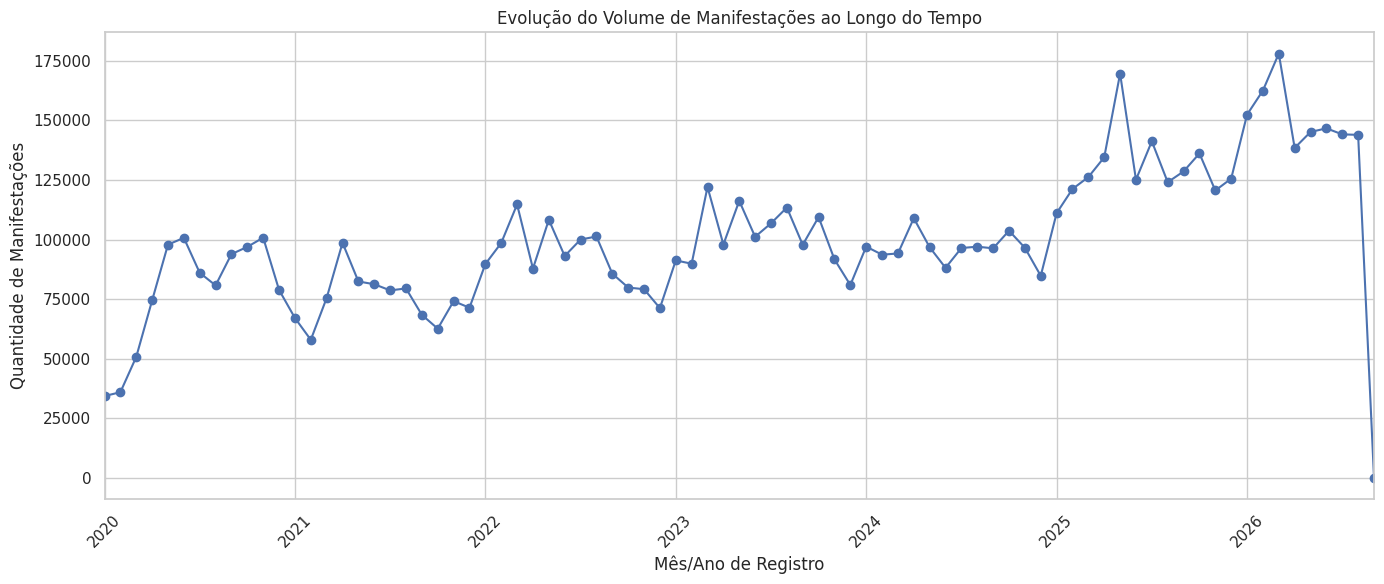

/tmp/ipykernel_451/3767584232.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='ano_registro', y='tempo_resposta_real', errorbar=None, palette='mako')


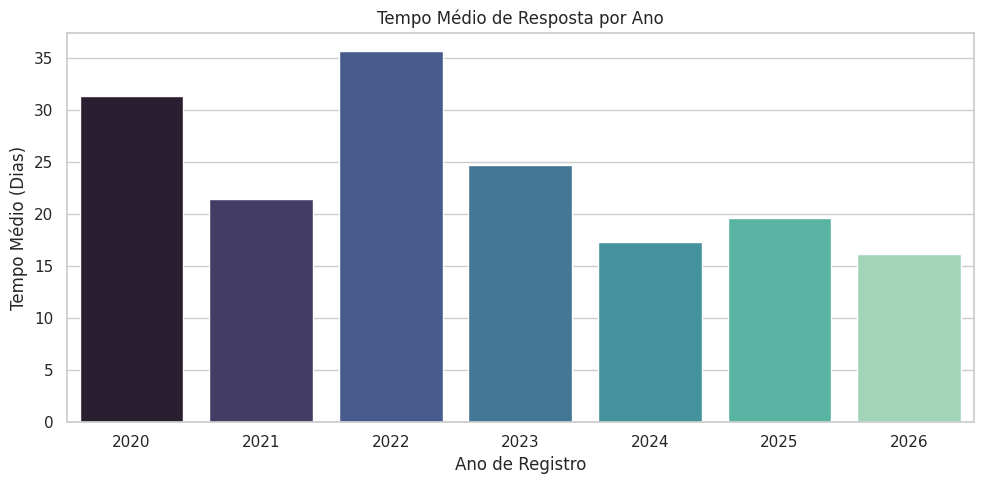

In [12]:
# 4. Gráficos Temporais
sns.set_theme(style="whitegrid")

# Gráfico 1: Evolução do número de manifestações por mês/ano
plt.figure(figsize=(14, 6))
# Agrupando por Ano-Mês e contando
ev_temporal = df.groupby('ano_mes_registro').size()
ev_temporal.plot(kind='line', marker='o', color='b')

plt.title('Evolução do Volume de Manifestações ao Longo do Tempo')
plt.xlabel('Mês/Ano de Registro')
plt.ylabel('Quantidade de Manifestações')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico 2: Tempo médio de resposta por ano
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='ano_registro', y='tempo_resposta_real', errorbar=None, palette='mako')
plt.title('Tempo Médio de Resposta por Ano')
plt.xlabel('Ano de Registro')
plt.ylabel('Tempo Médio (Dias)')
plt.tight_layout()
plt.show()

--- TIPOS DE MANIFESTAÇÃO MAIS FREQUENTES ---


,Quantidade,Porcentagem (%)
tipo manifestação,,
Reclamação,3808615,47.11
Solicitação,2686091,33.22
Comunicação,881474,10.90
Denúncia,489393,6.05
Elogio,130895,1.62
Sugestão,86503,1.07
Simplifique,1673,0.02


/tmp/ipykernel_451/1601638738.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


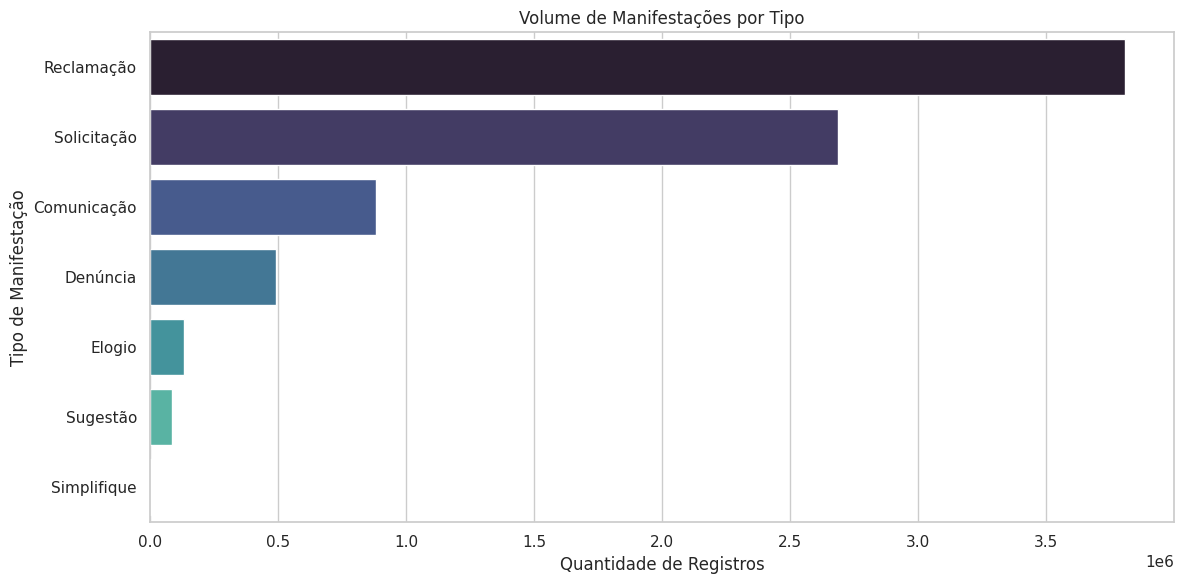

In [13]:
# 1. Calcular a quantidade e a porcentagem de cada tipo de manifestação
contagem_tipos = df['tipo manifestação'].value_counts()
porcentagem_tipos = df['tipo manifestação'].value_counts(normalize=True) * 100

# Criar um DataFrame para exibir os números exatos em formato de tabela
resumo_tipos = pd.DataFrame({
    'Quantidade': contagem_tipos,
    'Porcentagem (%)': porcentagem_tipos.round(2)
})

print("--- TIPOS DE MANIFESTAÇÃO MAIS FREQUENTES ---")
display(resumo_tipos)

# 2. Plotar o gráfico de barras horizontais
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    y='tipo manifestação',
    order=contagem_tipos.index,
    palette='mako'
)

plt.title('Volume de Manifestações por Tipo')
plt.xlabel('Quantidade de Registros')
plt.ylabel('Tipo de Manifestação')

# Ajusta o layout para que os nomes não fiquem cortados
plt.tight_layout()
plt.show()

Total de Reclamações em SP: 673970

--- TOP 10 ASSUNTOS DE RECLAMAÇÕES EM SÃO PAULO (SP) ---


,Quantidade,Porcentagem (%)
assunto,,
Outros em Previdência,130235,19.32
Benefícios e serviços,93442,13.86
Outros em Trabalho,44009,6.53
Receita Federal,35301,5.24
Auxílio,29265,4.34
Abono salarial,19386,2.88
Sistema Financeiro,18054,2.68
Seguro,15913,2.36
Fraude em auxílio emergencial - coronavírus,14181,2.10


/tmp/ipykernel_451/167825057.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


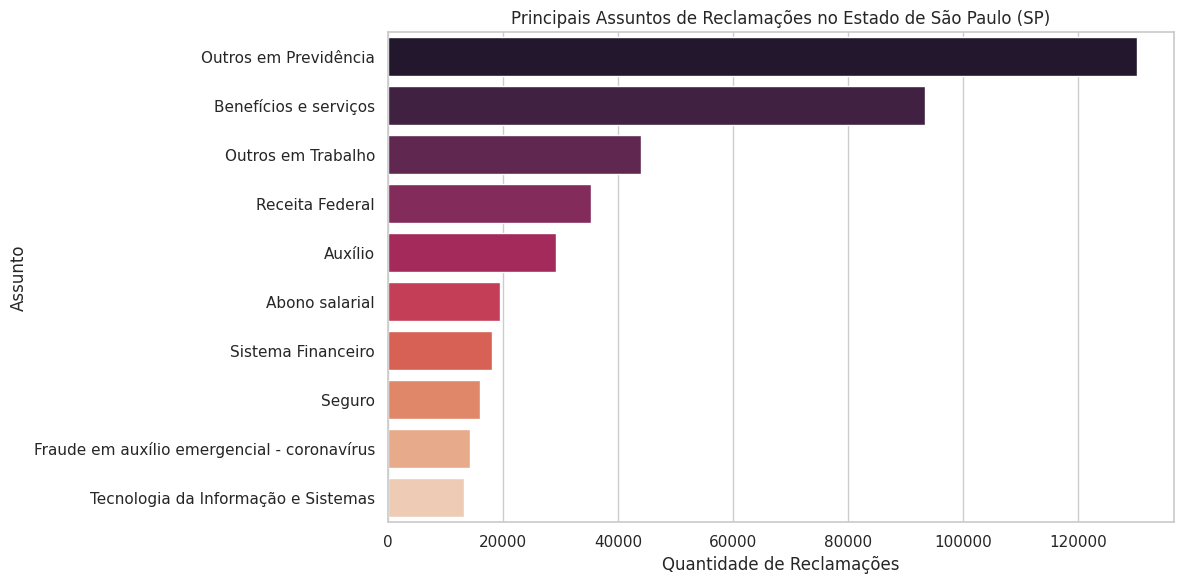

In [14]:
# 1. Filtrar os dados para o estado de São Paulo
# Usando 'uf do município manifestação' (onde o fato ocorreu)
df_sp = df[df['uf do município manifestação'] == 'SP'].copy()

# 2. Filtrar para manter apenas o tipo "Reclamação"
# O str.contains com case=False evita problemas com letras maiúsculas/minúsculas
df_sp_reclamacoes = df_sp[df_sp['tipo manifestação'].str.contains('Reclamação', case=False, na=False)]

# 3. Contar os 10 assuntos mais recorrentes dessas reclamações
top_assuntos_sp = df_sp_reclamacoes['assunto'].value_counts().head(10)

# 4. Criar um DataFrame para exibir os resultados em formato de tabela
resumo_assuntos_sp = pd.DataFrame({
    'Quantidade': top_assuntos_sp,
    'Porcentagem (%)': (top_assuntos_sp / len(df_sp_reclamacoes) * 100).round(2)
})

print(f"Total de Reclamações em SP: {len(df_sp_reclamacoes)}")
print("\n--- TOP 10 ASSUNTOS DE RECLAMAÇÕES EM SÃO PAULO (SP) ---")
display(resumo_assuntos_sp)

# 5. Gerar o gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_assuntos_sp.values,
    y=top_assuntos_sp.index,
    palette='rocket'
)

plt.title('Principais Assuntos de Reclamações no Estado de São Paulo (SP)')
plt.xlabel('Quantidade de Reclamações')
plt.ylabel('Assunto')

# Evita que os textos longos dos assuntos fiquem cortados
plt.tight_layout()
plt.show()

In [15]:
# 1. Definir palavras-chave do setor hospitalar/saúde
palavras_chave = 'hospital|saúde|saude|medic|ebserh|sus|clinica|clínica'

# 2. Criar uma máscara para buscar essas palavras nas colunas relevantes
mascara_saude = (
    df['nome Órgão'].str.contains(palavras_chave, case=False, na=False) |
    df['assunto'].str.contains(palavras_chave, case=False, na=False) |
    df['serviço'].str.contains(palavras_chave, case=False, na=False)
)

# 3. Filtrar apenas as Reclamações que se encaixam no setor de saúde
df_saude_reclamacoes = df[
    mascara_saude &
    df['tipo manifestação'].str.contains('Reclamação', case=False, na=False)
]

# 4. Gerar o relatório de diagnóstico para validação
print("--- COPIE E COLE A SAÍDA ABAIXO NO CHAT ---")
print(f"Total de reclamações mapeadas: {len(df_saude_reclamacoes)}")

print("\n1. TOP 10 ÓRGÃOS:")
print(df_saude_reclamacoes['nome Órgão'].value_counts().head(10).to_dict())

print("\n2. TOP 10 ASSUNTOS:")
print(df_saude_reclamacoes['assunto'].value_counts().head(10).to_dict())

print("\n3. TOP 10 SERVIÇOS:")
print(df_saude_reclamacoes['serviço'].value_counts().head(10).to_dict())

print("\n4. VALORES NULOS NESTE RECORTE (Potenciais buracos nos dados):")
print(df_saude_reclamacoes.isnull().sum()[df_saude_reclamacoes.isnull().sum() > 0].sort_values(ascending=False).head(5).to_dict())

--- COPIE E COLE A SAÍDA ABAIXO NO CHAT ---
Total de reclamações mapeadas: 285614

1. TOP 10 ÓRGÃOS:
{'Ministério da Saúde': 59887, 'Agência Nacional de Saúde Suplementar': 41377, 'Hospital Universitário': 17054, 'Prefeitura Municipal': 11467, 'Hospital das Clínicas': 11251, 'Hospital de Clínicas de Porto Alegre': 10810, 'EBSERH - Filial Complexo Hospitalar de Clínicas da Universidade Federal do Paraná': 9566, 'Secretaria Municipal de Saúde': 7636, 'Hospital Universitário de Brasília': 6128, 'Hospital Universitário Wálter Cantídio': 5563}

2. TOP 10 ASSUNTOS:
{'Assistência Hospitalar e Ambulatorial': 66514, 'Saúde Suplementar': 34399, 'Outros em Saúde': 27598, 'Atendimento': 21919, 'Ouvidoria Interna': 12763, 'Não Informado': 11027, 'Atendimento ao público': 8302, 'Planos de saúde': 7195, 'Medicamentos, aparelhos e produtos em saúde': 5037, 'Medicamentos e Aparelhos': 4888}

3. TOP 10 SERVIÇOS:
{'Reclamar sobre plano de saúde': 1009, 'Realizar consulta especializada': 996, 'Internar em

--- DESEMPENHO DE ATENDIMENTO: TOP 5 HOSPITAIS ---


,Volume_Reclamacoes,Tempo_Medio_Resposta_Dias,Maximo_Dias_Resposta
nome Órgão,,,
Hospital Universitário,17050,10.3,156.0
Hospital das Clínicas,11246,18.3,406.0
Hospital de Clínicas de Porto Alegre,10807,11.3,77.0
EBSERH - Filial Complexo Hospitalar de Clínicas da Universidade Federal do Paraná,8968,13.8,292.0
Hospital Universitário de Brasília,6128,9.6,123.0


/tmp/ipykernel_451/3565748877.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


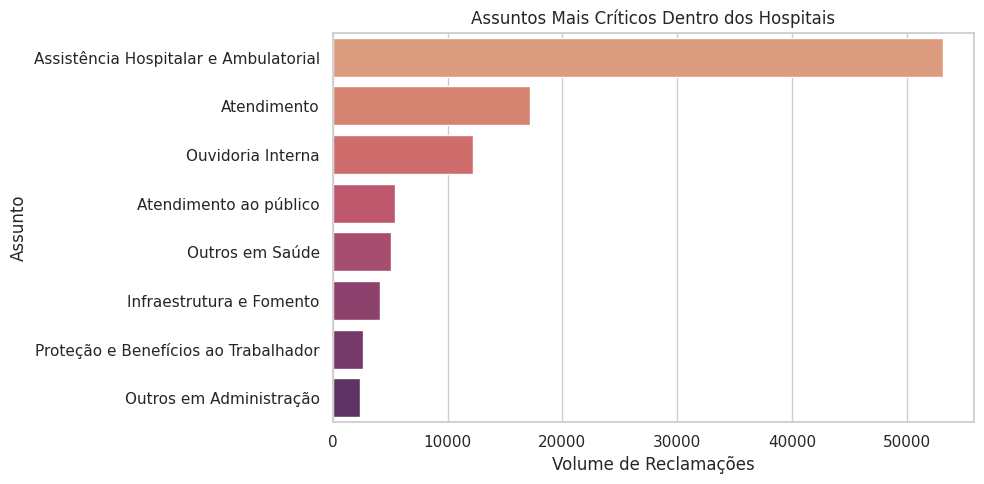

/tmp/ipykernel_451/3565748877.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


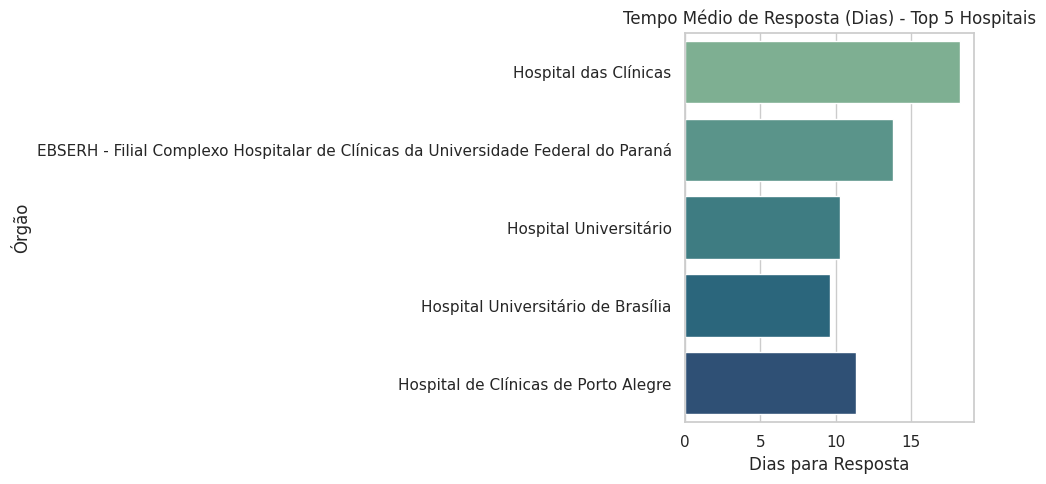

In [16]:
# 1. Isolar apenas os registros que mencionam "Hospital" no nome do Órgão
# Isso limpa ANS, Ministério da Saúde genérico e Prefeituras, focando na "ponta" do atendimento
df_hospitais = df_saude_reclamacoes[
    df_saude_reclamacoes['nome Órgão'].str.contains('Hospital|EBSERH|HCPA', case=False, na=False)
].copy()

# 2. Remover registros sem assunto definido
df_hospitais = df_hospitais[df_hospitais['assunto'] != 'Não Informado']

# 3. Analisar as métricas de tempo dos 5 Hospitais com mais reclamações
top_5_hospitais = df_hospitais['nome Órgão'].value_counts().head(5).index
df_top_5 = df_hospitais[df_hospitais['nome Órgão'].isin(top_5_hospitais)]

# Agrupando para ver a média de tempo de resposta e o volume
analise_tempo = df_top_5.groupby('nome Órgão').agg(
    Volume_Reclamacoes=('nome Órgão', 'count'),
    Tempo_Medio_Resposta_Dias=('tempo_resposta_real', 'mean'),
    Maximo_Dias_Resposta=('tempo_resposta_real', 'max')
).round(1).sort_values(by='Volume_Reclamacoes', ascending=False)

print("--- DESEMPENHO DE ATENDIMENTO: TOP 5 HOSPITAIS ---")
display(analise_tempo)

# 4. Visualizar os Assuntos mais críticos dentro do ambiente estritamente hospitalar
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_hospitais,
    y='assunto',
    order=df_hospitais['assunto'].value_counts().head(8).index,
    palette='flare'
)
plt.title('Assuntos Mais Críticos Dentro dos Hospitais')
plt.xlabel('Volume de Reclamações')
plt.ylabel('Assunto')
plt.tight_layout()
plt.show()

# 5. Visualizar o Tempo Médio de Resposta por Hospital
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_top_5,
    y='nome Órgão',
    x='tempo_resposta_real',
    errorbar=None,
    palette='crest'
)
plt.title('Tempo Médio de Resposta (Dias) - Top 5 Hospitais')
plt.xlabel('Dias para Resposta')
plt.ylabel('Órgão')
plt.tight_layout()
plt.show()

--- ANÁLISE DE VIOLAÇÃO DE PRAZO (SLA > 30 DIAS) ---


,Volume_Total,Volume_Estouro_SLA,Taxa_Falha_SLA (%)
nome Órgão,,,
Hospital das Clínicas,11246,2120,18.85
EBSERH - Filial Complexo Hospitalar de Clínicas da Universidade Federal do Paraná,8968,868,9.68
Hospital Universitário,17050,749,4.39
Hospital de Clínicas de Porto Alegre,10807,425,3.93
Hospital Universitário de Brasília,6128,126,2.06



--- TOP 5 ASSUNTOS QUE MAIS GERAM ATRASOS CRÍTICOS ---


,Volume de Atrasos
assunto_agrupado,
Assistência Hospitalar e Ambulatorial,3319
Atendimento,1974
Ouvidoria Interna,1674
Outros em Saúde,463
Proteção e Benefícios ao Trabalhador,272


/tmp/ipykernel_451/190964512.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


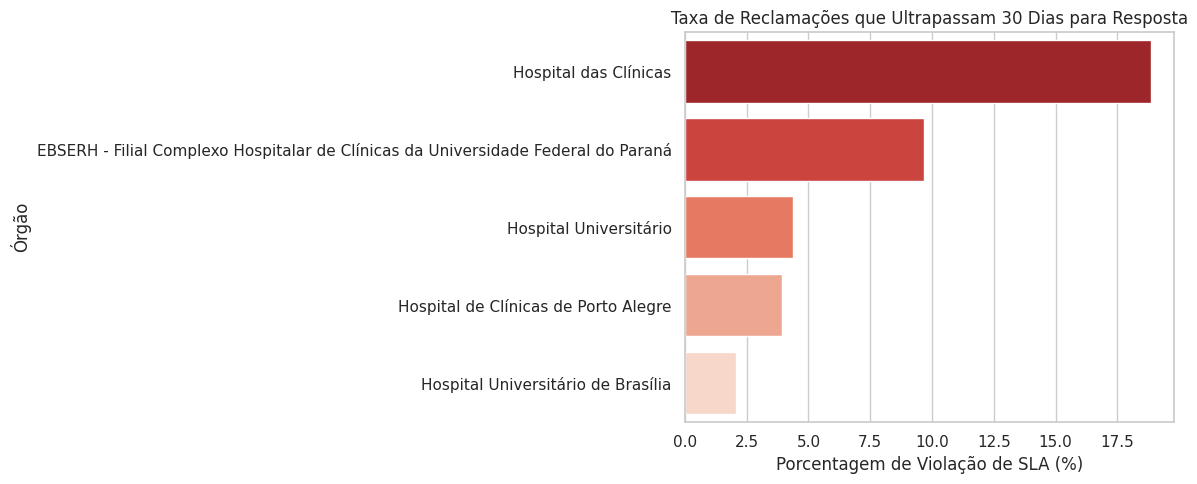

In [17]:
# 1. Unificar categorias redundantes de Assunto
df_hospitais['assunto_agrupado'] = df_hospitais['assunto'].replace({
    'Atendimento ao público': 'Atendimento'
})

# 2. Definir o limite de SLA (ex: 30 dias, prazo padrão de ouvidorias públicas)
limite_sla_dias = 30

# 3. Criar uma flag para reclamações que estouraram o SLA
df_hospitais['estourou_sla'] = df_hospitais['tempo_resposta_real'] > limite_sla_dias

# 4. Calcular a taxa de estouro de SLA por hospital (focando no Top 5)
analise_sla = df_hospitais[df_hospitais['nome Órgão'].isin(top_5_hospitais)].groupby('nome Órgão').agg(
    Volume_Total=('nome Órgão', 'count'),
    Volume_Estouro_SLA=('estourou_sla', 'sum')
)

# Calcula a porcentagem de tickets que violaram o prazo
analise_sla['Taxa_Falha_SLA (%)'] = (analise_sla['Volume_Estouro_SLA'] / analise_sla['Volume_Total'] * 100).round(2)
analise_sla = analise_sla.sort_values(by='Taxa_Falha_SLA (%)', ascending=False)

print("--- ANÁLISE DE VIOLAÇÃO DE PRAZO (SLA > 30 DIAS) ---")
display(analise_sla)

# 5. Analisar quais são os Assuntos que mais estouram o SLA
assuntos_criticos = df_hospitais[df_hospitais['estourou_sla'] == True]['assunto_agrupado'].value_counts().head(5)

print("\n--- TOP 5 ASSUNTOS QUE MAIS GERAM ATRASOS CRÍTICOS ---")
display(pd.DataFrame({'Volume de Atrasos': assuntos_criticos}))

# 6. Gráfico da Taxa de Falha
plt.figure(figsize=(12, 5))
sns.barplot(
    data=analise_sla.reset_index(),
    y='nome Órgão',
    x='Taxa_Falha_SLA (%)',
    palette='Reds_r'
)
plt.title('Taxa de Reclamações que Ultrapassam 30 Dias para Resposta')
plt.xlabel('Porcentagem de Violação de SLA (%)')
plt.ylabel('Órgão')
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd

caminho_estabelecimentos = '/content/drive/MyDrive/Dados_Publicos_Saude/tbEstabelecimento202608.csv'
caminho_equipamentos = '/content/drive/MyDrive/Dados_Publicos_Saude/rlEstabEquipamento202608.csv'

# 1. Carregar os Dados de Estabelecimentos
df_estabelecimentos = pd.read_csv(
    caminho_estabelecimentos,
    sep=';',
    encoding='latin1',
    low_memory=False,
    on_bad_lines='skip'
)

# Limpar possíveis aspas dos nomes das colunas
df_estabelecimentos.columns = df_estabelecimentos.columns.str.replace('"', '').str.strip()

# 2. Filtrar SP (Código IBGE 35)
if 'CO_ESTADO_GESTOR' in df_estabelecimentos.columns:
    df_hospitais_sp = df_estabelecimentos[df_estabelecimentos['CO_ESTADO_GESTOR'] == 35].copy()
else:
    df_hospitais_sp = df_estabelecimentos.head(100).copy()

print(f"Hospitais encontrados em SP: {len(df_hospitais_sp)}")

# 3. Carregar os Dados de Equipamentos
df_equipamentos = pd.read_csv(
    caminho_equipamentos,
    sep=';',
    encoding='latin1',
    low_memory=False
)

# Limpar possíveis aspas dos nomes das colunas dos equipamentos
df_equipamentos.columns = df_equipamentos.columns.str.replace('"', '').str.strip()

print("Colunas limpas em Hospitais:", [c for c in df_hospitais_sp.columns if 'CO_' in c or 'NO_' in c][:10])
print("Colunas limpas em Equipamentos:", df_equipamentos.columns.tolist()[:10])

# 4. Garantir que os dados das colunas de cruzamento não tenham aspas nos valores
for col in ['CO_UNIDADE', 'CO_CNES', 'NO_FANTASIA']:
    if col in df_hospitais_sp.columns:
        df_hospitais_sp[col] = df_hospitais_sp[col].astype(str).str.replace('"', '').str.strip()

if 'CO_UNIDADE' in df_equipamentos.columns:
    df_equipamentos['CO_UNIDADE'] = df_equipamentos['CO_UNIDADE'].astype(str).str.replace('"', '').str.strip()

    # 5. Cruzar (Merge) os dados usando o Código Interno ('CO_UNIDADE') que agora existe e está limpo
    df_infra_sp = pd.merge(
        df_hospitais_sp[['CO_UNIDADE', 'CO_CNES', 'NO_FANTASIA']],
        df_equipamentos,
        on='CO_UNIDADE',
        how='inner'
    )

    print(f"Total de registros de equipamentos cruzados com sucesso em SP: {len(df_infra_sp)}")
    display(df_infra_sp.head())
else:
    print("ERRO: A coluna 'CO_UNIDADE' não foi encontrada em df_equipamentos. Verifique se o arquivo tbEquipamento202608.csv está correto.")
    df_infra_sp = pd.DataFrame() # DataFrame vazio para evitar erros em células posteriores

Hospitais encontrados em SP: 152673
Colunas limpas em Hospitais: ['CO_UNIDADE', 'CO_CNES', 'NO_RAZAO_SOCIAL', 'NO_FANTASIA', 'NO_LOGRADOURO', 'NO_COMPLEMENTO', 'NO_BAIRRO', 'CO_CEP', 'CO_REGIAO_SAUDE', 'CO_MICRO_REGIAO']
Colunas limpas em Equipamentos: ['CO_UNIDADE', 'CO_EQUIPAMENTO', 'CO_TIPO_EQUIPAMENTO', 'QT_EXISTENTE', 'QT_USO', 'TP_SUS', 'QT_SUS', "TO_CHAR(DT_ATUALIZACAO,'DD/MM/YYYY')", 'CO_USUARIO', "TO_CHAR(DT_ATUALIZACAO_ORIGEM,'DD/MM/YYYY')"]
Total de registros de equipamentos cruzados com sucesso em SP: 187706


,CO_UNIDADE,CO_CNES,NO_FANTASIA,CO_EQUIPAMENTO,CO_TIPO_EQUIPAMENTO,QT_EXISTENTE,QT_USO,TP_SUS,QT_SUS,"TO_CHAR(DT_ATUALIZACAO,'DD/MM/YYYY')",CO_USUARIO,"TO_CHAR(DT_ATUALIZACAO_ORIGEM,'DD/MM/YYYY')"
0,3552402057972,2057972,USF CS II,7,1,1,1,1.0,1.0,08/09/2026,FERNANDA,NaN
1,3552402057972,2057972,USF CS II,62,5,10,7,1.0,7.0,08/09/2026,FERNANDA,NaN
2,3552402057972,2057972,USF CS II,63,5,1,1,1.0,1.0,08/09/2026,FERNANDA,NaN
3,3552402057972,2057972,USF CS II,80,7,2,2,1.0,2.0,08/09/2026,FERNANDA,NaN
4,3543702747197,2747197,CLINICA DE FISIOTERAPIA RINCAO,19,2,3,3,1.0,3.0,08/09/2026,SAUDE,NaN


Depois de carregar todas as tabelas, aqui está a consolidação

In [19]:
# 1. Carregar o Dicionário
caminho_tipo_equip = '/content/drive/MyDrive/Dados_Publicos_Saude/tbTipoEquipamento202608.csv'
df_tipo_equip = pd.read_csv(caminho_tipo_equip, sep=';', encoding='latin1')

# Nomes exatos baseados no seu print
col_dicionario_codigo = 'CO_TIPO_EQUIPAMENTO'
col_dicionario_nome = 'DS_TIPO_EQUIPAMENTO'

# Identifica como a coluna de código se chama na tabela principal (df_infra_sp)
col_infra_codigo = 'CO_EQUIPAMENTO' if 'CO_EQUIPAMENTO' in df_infra_sp.columns else 'CO_TIPO_EQUIPAMENTO'

# 2. Fazer o merge (cruzamento) ligando as colunas corretas de cada lado
df_infra_sp_nomes = pd.merge(
    df_infra_sp,
    df_tipo_equip[[col_dicionario_codigo, col_dicionario_nome]],
    left_on=col_infra_codigo,
    right_on=col_dicionario_codigo,
    how='left'
)

# 3. Consolidação 1: Equipamentos mais comuns em SP
resumo_equipamentos_sp = df_infra_sp_nomes.groupby(col_dicionario_nome).agg(
    Hospitais_com_Equipamento=('CO_CNES', 'nunique'),
    Total_Existente=('QT_EXISTENTE', 'sum'),
    Total_Em_Uso=('QT_USO', 'sum')
).sort_values(by='Total_Existente', ascending=False)

print("\n--- TOP 10 EQUIPAMENTOS MAIS COMUNS EM SP ---")
display(resumo_equipamentos_sp.head(10))

# 4. Consolidação 2: Inventário focado por Hospital
nome_hospital_busca = 'CLINICAS' # Altere aqui para buscar outros hospitais

inventario_hospital = df_infra_sp_nomes[
    df_infra_sp_nomes['NO_FANTASIA'].str.contains(nome_hospital_busca, case=False, na=False)
].groupby(['NO_FANTASIA', col_dicionario_nome]).agg(
    Total_Existente=('QT_EXISTENTE', 'sum'),
    Total_Em_Uso=('QT_USO', 'sum')
)

print(f"\n--- INVENTÁRIO: HOSPITAIS CONTENDO '{nome_hospital_busca}' NO NOME ---")
display(inventario_hospital.head(15))


--- TOP 10 EQUIPAMENTOS MAIS COMUNS EM SP ---


,Hospitais_com_Equipamento,Total_Existente,Total_Em_Uso
DS_TIPO_EQUIPAMENTO,,,
ODONTOLOGIA,20121,23983,23040
DIAGNOSTICO POR IMAGEM,1683,10637,10144
PROCEDIMENTOS CLINICOS,4705,7053,6796
QUIMIOTERAPIA,3759,6307,6137
Equipamentos de Infra-Estrutura,1294,3548,3492
MANUTENCAO DA VIDA,2428,3420,3276
Equipamentos por Metodos Graficos,2051,3392,3225
REABILITACAO,2234,2923,2849
Equipamentos por Metodos Opticos,582,1887,1732



--- INVENTÁRIO: HOSPITAIS CONTENDO 'CLINICAS' NO NOME ---


Total_Existente  \
NO_FANTASIA                                        DS_TIPO_EQUIPAMENTO                                  
AMBULATORIO DONA BALBINA CLINICAS                  QUIMIOTERAPIA                                    1   
ARR LABORATORIO DE ANALISES CLINICAS               PROCEDIMENTOS CLINICOS                           1   
ARTE DE SORRIR CLINICAS ODONTOLOGICAS              ODONTOLOGIA                                      1   
BIO CIENCIA LAVOSIER ANALISES CLINICAS             PROCEDIMENTOS CLINICOS                           2   
BIOLABOR LABORATORIO DE ANALISES CLINICAS LTDA ... MANUTENCAO DA VIDA                               1   
                                                   QUIMIOTERAPIA                                    1   
                                                   REABILITACAO                                     1   
BIOLABOR LABORATORIO DE ANALISES CLINICAS SOROCABA DIAGNOSTICO POR IMAGEM                           1   
                                                   QUIMIOTERAPIA                                    1   
                                                   RADIOTERAPIA                                     1   
CELAC CENTRO DE ESP E LAB DE AN CLINICAS           Equipamentos de Infra-Estrutura                  1   
                                                   PROCEDIMENTOS CLINICOS                           1   
                                                   QUIMIOTERAPIA                                    1   
CENTER CLINICAS                                    REABILITACAO                                     1   
CENTRAL DE ESPECIALIDADES CLINICAS S S LTDA        Equipamentos por Metodos Graficos                1   

                                                                                      Total_Em_Uso  
NO_FANTASIA                                        DS_TIPO_EQUIPAMENTO                              
AMBULATORIO DONA BALBINA CLINICAS                  QUIMIOTERAPIA                                 1  
ARR LABORATORIO DE ANALISES CLINICAS               PROCEDIMENTOS CLINICOS                        1  
ARTE DE SORRIR CLINICAS ODONTOLOGICAS              ODONTOLOGIA                                   1  
BIO CIENCIA LAVOSIER ANALISES CLINICAS             PROCEDIMENTOS CLINICOS                        2  
BIOLABOR LABORATORIO DE ANALISES CLINICAS LTDA ... MANUTENCAO DA VIDA                            1  
                                                   QUIMIOTERAPIA                                 1  
                                                   REABILITACAO                                  1  
BIOLABOR LABORATORIO DE ANALISES CLINICAS SOROCABA DIAGNOSTICO POR IMAGEM                        1  
                                                   QUIMIOTERAPIA                                 1  
                                                   RADIOTERAPIA                                  1  
CELAC CENTRO DE ESP E LAB DE AN CLINICAS           Equipamentos de Infra-Estrutura               1  
                                                   PROCEDIMENTOS CLINICOS                        1  
                                                   QUIMIOTERAPIA                                 1  
CENTER CLINICAS                                    REABILITACAO                                  1  
CENTRAL DE ESPECIALIDADES CLINICAS S S LTDA        Equipamentos por Metodos Graficos             1

**TESTE DE PROJETO AI**

In [20]:
!pip install thefuzz

import pandas as pd
from thefuzz import process

# 1. Isolar os nomes únicos de hospitais da Ouvidoria (para não processar 285 mil linhas à toa)
# Usaremos o df_hospitais que você já filtrou nos passos anteriores
nomes_ouvidoria = df_hospitais['nome Órgão'].dropna().unique()

# 2. Criar uma lista com os nomes oficiais do CNES (focando em SP)
nomes_cnes = df_hospitais_sp['NO_FANTASIA'].dropna().unique()

# 3. Aplicar Fuzzy Matching para encontrar o par mais similar
mapeamento = []
print("Iniciando o cruzamento de nomes (isso pode levar alguns segundos)...")

for nome_ouv in nomes_ouvidoria:
    # Retorna o melhor match e a pontuação de similaridade (0 a 100)
    melhor_match, pontuacao = process.extractOne(nome_ouv, nomes_cnes)

    # Filtro de segurança: só aceitamos se a similaridade for maior que 85%
    if pontuacao >= 85:
        mapeamento.append({
            'Nome_Ouvidoria': nome_ouv,
            'Nome_CNES_Match': melhor_match,
            'Score_Similaridade': pontuacao
        })

# 4. Transformar o mapeamento em um DataFrame (A "Ponte")
df_ponte = pd.DataFrame(mapeamento)
print("\n--- RESULTADO DO FUZZY MATCHING (AMOSTRA) ---")
display(df_ponte.head())

# 5. O Cruzamento Final (Unindo Ouvidoria + Ponte + CNES Infraestrutura)
# A. Adiciona o nome oficial do CNES na base de reclamações
df_reclamacoes_cruzadas = pd.merge(
    df_hospitais,
    df_ponte,
    left_on='nome Órgão',
    right_on='Nome_Ouvidoria',
    how='inner'
)

# B. Cruza com a base de equipamentos (df_infra_sp_nomes) gerada no passo anterior
# Para evitar duplicar milhares de linhas (já que um hospital tem vários equipamentos),
# primeiro consolidamos os equipamentos essenciais (ex: Tomógrafo) por hospital.

# Filtrando apenas equipamentos críticos no CNES
equipamentos_criticos = df_infra_sp_nomes[
    df_infra_sp_nomes['DS_TIPO_EQUIPAMENTO'].str.contains('TOMOGRAFO|RESSONANCIA|RAIO X', case=False, na=False)
]

# Agrupando a infraestrutura por hospital
infra_consolidada = equipamentos_criticos.groupby('NO_FANTASIA').agg(
    Equipamentos_Criticos_Total=('QT_EXISTENTE', 'sum'),
    Equipamentos_Criticos_Em_Uso=('QT_USO', 'sum')
).reset_index()

# Calcula o déficit físico (equipamentos quebrados/parados)
infra_consolidada['Equipamentos_Parados'] = infra_consolidada['Equipamentos_Criticos_Total'] - infra_consolidada['Equipamentos_Criticos_Em_Uso']

# C. Merge Final Definitivo
df_case_final = pd.merge(
    df_reclamacoes_cruzadas,
    infra_consolidada,
    left_on='Nome_CNES_Match',
    right_on='NO_FANTASIA',
    how='left'
)

print("\n--- CONSOLIDAÇÃO FINAL DO CASE ---")
# Exibe reclamações críticas que estouraram o prazo, cruzadas com a taxa de equipamentos parados no mesmo hospital
resultado_final = df_case_final[df_case_final['estourou_sla'] == True].groupby('Nome_CNES_Match').agg(
    Reclamacoes_Atrasadas=('nome Órgão', 'count'),
    Dias_Maximo_Atraso=('tempo_resposta_real', 'max'),
    Equip_Criticos_Total=('Equipamentos_Criticos_Total', 'max'),
    Equip_Criticos_Parados=('Equipamentos_Parados', 'max')
).sort_values(by='Reclamacoes_Atrasadas', ascending=False)

display(resultado_final)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.6 MB/s eta 0:00:00
Iniciando o cruzamento de nomes (isso pode levar alguns segundos)...

--- RESULTADO DO FUZZY MATCHING (AMOSTRA) ---


,Nome_Ouvidoria,Nome_CNES_Match,Score_Similaridade
0,Grupo Hospitalar Conceição S.A,CONSULTORIO ISOLADO CLJ SALGADO DE S PREST SER...,86
1,EBSERH - Filial Hospital Universitário Edgard ...,JACQUELINE SANTOS OLIVEIRA,86
2,Hospital das Clínicas,CAS,90
3,EBSERH - Filial Complexo Hospitalar de Clínica...,COMPLEXO HOSPITALAR DE CLINICAS,87
4,Hospital das Clinicas,HOSPITAL DAS CLINICAS BAURU,95



--- CONSOLIDAÇÃO FINAL DO CASE ---


,Reclamacoes_Atrasadas,Dias_Maximo_Atraso,Equip_Criticos_Total,Equip_Criticos_Parados
Nome_CNES_Match,,,,
CAS,2120,406.0,NaN,NaN
CLINICA DE FISIOTERAPIA RINCAO,1361,516.0,NaN,NaN
HOSPITAL SANTA EDWIGES,1218,222.0,NaN,NaN
COMPLEXO HOSPITALAR DE CLINICAS,868,292.0,NaN,NaN
HU HOSPITAL UNIVERSITARIO,749,156.0,NaN,NaN
HOSPITAL SANCTA MAGGIORE,739,475.0,NaN,NaN
SERVICO DE FISIOTERAPIA,594,110.0,NaN,NaN
JACQUELINE SANTOS OLIVEIRA,488,93.0,NaN,NaN
CENTRO DE REFERENCIA EM SAUDE DO TRABALHADOR CEREST BAURU,327,274.0,NaN,NaN


Tratamento do dataframe

In [21]:
import pandas as pd
import unicodedata
import numpy as np

# 1. Função para padronização de texto
def limpar_texto(texto):
    if pd.isna(texto):
        return texto
    texto = str(texto).strip().upper()
    texto = ''.join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')
    return texto

print("Iniciando o pipeline de tratamento de dados...")

# 2. Remoção de Ruídos e Colunas Inúteis
colunas_para_remover = ['outro serviço', 'serviço', 'demanda atendida', 'satisfação', 'dias de atraso']
df_clean = df_hospitais.drop(columns=[col for col in colunas_para_remover if col in df_hospitais.columns]).copy()

# 3. Padronização de Colunas Chave
print("- Padronizando nomes de órgãos e assuntos...")
df_clean['nome_orgao_padrao'] = df_clean['nome Órgão'].apply(limpar_texto)
df_clean['assunto_padrao'] = df_clean['assunto'].apply(limpar_texto)

termos_remover = ['EBSERH - FILIAL COMPLEXO HOSPITALAR DE CLINICAS DA UNIVERSIDADE FEDERAL DO PARANA', 'EBSERH - ']
for termo in termos_remover:
    df_clean['nome_orgao_padrao'] = df_clean['nome_orgao_padrao'].str.replace(termo, '', regex=False)

# 4. Engenharia de Recursos (Feature Engineering)
print("- Criando categorias de SLA e tempo...")
condicoes_sla = [
    (df_clean['tempo_resposta_real'] <= 30),
    (df_clean['tempo_resposta_real'] > 30) & (df_clean['tempo_resposta_real'] <= 60),
    (df_clean['tempo_resposta_real'] > 60) & (df_clean['tempo_resposta_real'] <= 120),
    (df_clean['tempo_resposta_real'] > 120)
]
categorias_sla = ['No Prazo (<=30 dias)', 'Atraso Moderado (31-60 dias)', 'Atraso Crítico (61-120 dias)', 'Colapso de Atendimento (>120 dias)']
df_clean['categoria_atraso'] = np.select(condicoes_sla, categorias_sla, default='Não Calculado')

df_clean['trimestre_registro'] = df_clean['data registro'].dt.quarter

# Correção: Extraindo em inglês e mapeando para português sem usar o locale do sistema
dias_traducao = {
    'Monday': 'Segunda-feira',
    'Tuesday': 'Terça-feira',
    'Wednesday': 'Quarta-feira',
    'Thursday': 'Quinta-feira',
    'Friday': 'Sexta-feira',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}
df_clean['dia_semana_registro'] = df_clean['data registro'].dt.day_name().map(dias_traducao)

# 5. Tratamento de Outliers
df_clean = df_clean[df_clean['tempo_resposta_real'] >= 0]

print("Pipeline concluído!")
print(f"\nTotal de registros válidos: {len(df_clean)}")

print("\n--- DISTRIBUIÇÃO DO TEMPO DE RESPOSTA ---")
display(df_clean['categoria_atraso'].value_counts(normalize=True).round(4) * 100)

Iniciando o pipeline de tratamento de dados...
- Padronizando nomes de órgãos e assuntos...
- Criando categorias de SLA e tempo...
Pipeline concluído!

Total de registros válidos: 120798

--- DISTRIBUIÇÃO DO TEMPO DE RESPOSTA ---


,proportion
categoria_atraso,
No Prazo (<=30 dias),91.63
Atraso Moderado (31-60 dias),6.70
Atraso Crítico (61-120 dias),1.51
Colapso de Atendimento (>120 dias),0.16


descobrindo equipamentos com tempo ocioso

Encontrados 9402 registros de equipamentos parados/subutilizados em SP.

--- TOP 10 EQUIPAMENTOS COM MAIOR VOLUME DE OCIOSIDADE ---


,Hospitais_Afetados,Total_Existente,Total_Parado,%_Parado_Geral
DS_TIPO_EQUIPAMENTO,,,,
ODONTOLOGIA,619,1271,943,74.19
DIAGNOSTICO POR IMAGEM,123,3310,493,14.89
PROCEDIMENTOS CLINICOS,199,516,257,49.81
QUIMIOTERAPIA,119,280,170,60.71
Equipamentos por Metodos Graficos,105,286,167,58.39
Equipamentos por Metodos Opticos,48,171,155,90.64
MANUTENCAO DA VIDA,100,254,144,56.69
AUDIOLOGIA,23,137,126,91.97
REABILITACAO,65,109,74,67.89



--- TOP 10 HOSPITAIS COM EQUIPAMENTOS DE IMAGEM PARADOS ---


,Tipos_Equipamentos_Afetados,Total_Maquinas_Paradas
NO_FANTASIA,,


/tmp/ipykernel_451/3095670635.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


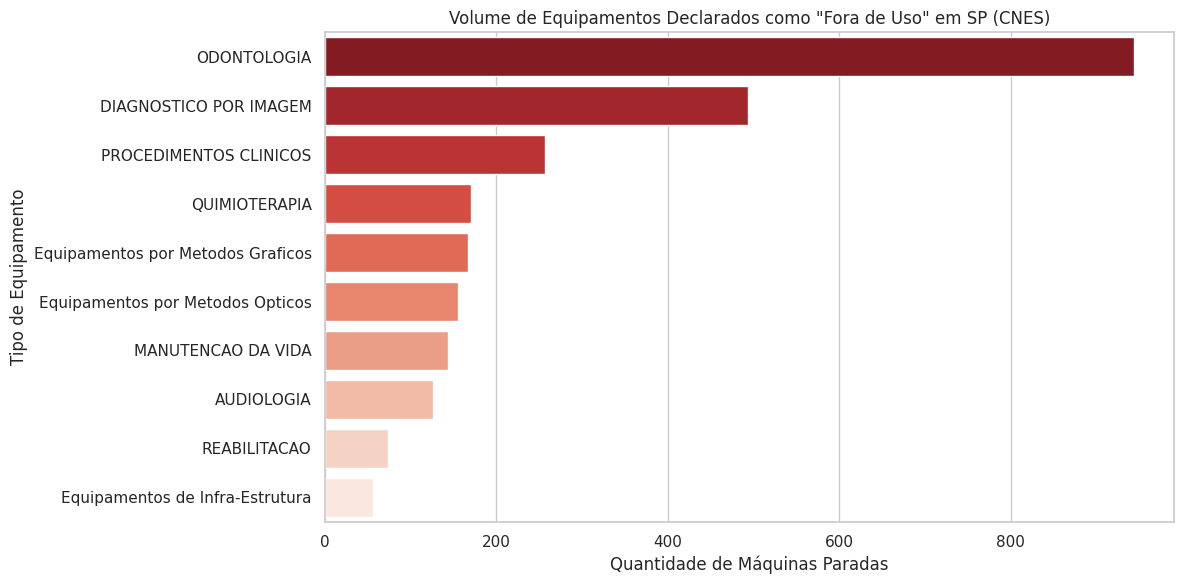

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

# 1. Garantir que as variáveis necessárias estejam recriadas/carregadas caso tenham falhado anteriormente
caminho_equipamentos = '/content/drive/MyDrive/Dados_Publicos_Saude/Equipamentos_202608.csv' # ajuste o nome exato se necessário

# Caso o caminho_equipamentos genérico precise de busca por glob
arquivos_equip = glob.glob('/content/drive/MyDrive/Dados_Publicos_Saude/Equipamentos_*.csv')
if arquivos_equip:
    caminho_equipamentos = arquivos_equip[0]

try:
    # Carregar equipamentos se não estiver na memória
    if 'df_equipamentos' not in locals() or 'df_equipamentos' not in globals():
        df_equipamentos = pd.read_csv(
            caminho_equipamentos,
            sep=';',
            encoding='latin1',
            low_memory=False
        )

    # Cruzar dados com os hospitais de SP
    if 'df_infra_sp_nomes' not in locals() or 'df_infra_sp_nomes' not in globals():
        df_infra_sp = pd.merge(
            df_hospitais_sp[['CO_UNIDADE', 'CO_CNES', 'NO_FANTASIA']],
            df_equipamentos,
            on='CO_UNIDADE',
            how='inner'
        )

        col_dicionario_codigo = 'CO_TIPO_EQUIPAMENTO'
        col_dicionario_nome = 'DS_TIPO_EQUIPAMENTO'
        col_infra_codigo = 'CO_EQUIPAMENTO' if 'CO_EQUIPAMENTO' in df_infra_sp.columns else 'CO_TIPO_EQUIPAMENTO'

        df_infra_sp_nomes = pd.merge(
            df_infra_sp,
            df_tipo_equip[[col_dicionario_codigo, col_dicionario_nome]],
            left_on=col_infra_codigo,
            right_on=col_dicionario_codigo,
            how='left'
        )
except Exception as e:
    print(f"Erro ao reconstruir df_infra_sp_nomes: {e}")

# --- Agora prosseguimos com o script original com segurança ---
if 'df_infra_sp_nomes' in locals() or 'df_infra_sp_nomes' in globals():
    # 1. Calcular a quantidade de equipamentos PARADOS/OCIOSOS
    df_infra_sp_nomes['QT_PARADA'] = df_infra_sp_nomes['QT_EXISTENTE'] - df_infra_sp_nomes['QT_USO']

    # 2. Filtrar apenas registros onde há equipamentos parados e evitar divisão por zero
    df_ocioso = df_infra_sp_nomes[df_infra_sp_nomes['QT_PARADA'] > 0].copy()
    df_ocioso['Taxa_Ociosidade_%'] = (df_ocioso['QT_PARADA'] / df_ocioso['QT_EXISTENTE'] * 100).round(2)

    print(f"Encontrados {len(df_ocioso)} registros de equipamentos parados/subutilizados em SP.")

    # 3. VISÃO 1: QUAIS EQUIPAMENTOS ESTÃO MAIS QUEBRADOS/PARADOS NO ESTADO?
    equipamentos_criticos = df_ocioso.groupby('DS_TIPO_EQUIPAMENTO').agg(
        Hospitais_Afetados=('CO_CNES', 'nunique'),
        Total_Existente=('QT_EXISTENTE', 'sum'),
        Total_Parado=('QT_PARADA', 'sum')
    )

    equipamentos_criticos['%_Parado_Geral'] = (equipamentos_criticos['Total_Parado'] / equipamentos_criticos['Total_Existente'] * 100).round(2)
    equipamentos_criticos = equipamentos_criticos.sort_values(by='Total_Parado', ascending=False)

    print("\n--- TOP 10 EQUIPAMENTOS COM MAIOR VOLUME DE OCIOSIDADE ---")
    display(equipamentos_criticos.head(10))

    # 4. VISÃO 2: QUAIS HOSPITAIS TÊM O PIOR APROVEITAMENTO DE MÁQUINAS?
    equip_alto_custo = ['TOMOGRAFO COMPUTADORIZADO', 'MAMOGRAFO COMPUTADORIZADO', 'EQUIPAMENTO DE RAIOS X', 'RESSONANCIA MAGNETICA']

    hospitais_criticos = df_ocioso[df_ocioso['DS_TIPO_EQUIPAMENTO'].isin(equip_alto_custo)].groupby('NO_FANTASIA').agg(
        Tipos_Equipamentos_Afetados=('DS_TIPO_EQUIPAMENTO', 'unique'),
        Total_Maquinas_Paradas=('QT_PARADA', 'sum')
    ).sort_values(by='Total_Maquinas_Paradas', ascending=False)

    hospitais_criticos['Tipos_Equipamentos_Afetados'] = hospitais_criticos['Tipos_Equipamentos_Afetados'].apply(lambda x: ', '.join(x))

    print("\n--- TOP 10 HOSPITAIS COM EQUIPAMENTOS DE IMAGEM PARADOS ---")
    display(hospitais_criticos.head(10))

    # 5. Visualização Gráfica do Desperdício
    plt.figure(figsize=(12, 6))
    top_10_grafico = equipamentos_criticos.head(10)
    sns.barplot(
        x=top_10_grafico['Total_Parado'],
        y=top_10_grafico.index,
        palette='Reds_r'
    )
    plt.title('Volume de Equipamentos Declarados como "Fora de Uso" em SP (CNES)')
    plt.xlabel('Quantidade de Máquinas Paradas')
    plt.ylabel('Tipo de Equipamento')
    plt.tight_layout()
    plt.show()
else:
    print("Não foi possível executar a análise pois a variável 'df_infra_sp_nomes' não foi definida corretamente.")

IDENTIFICANDO GARGALO EM ODONTOLOGIA

In [23]:
import pandas as pd
import csv

caminho_rh_geral = '/content/drive/MyDrive/Dados_Publicos_Saude/tbCargaHorariaSus202608.csv'

print("Lendo a base geral de profissionais do SUS (isto pode demorar 1-2 minutos devido ao tamanho)...")

# SOLUÇÃO: Pedir as colunas exatamente como estão no texto bruto do CSV (com as aspas)
colunas_necessarias = ['"CO_UNIDADE"', '"CO_CBO"']

try:
    df_rh_geral = pd.read_csv(
        caminho_rh_geral,
        sep=';',
        encoding='latin1',
        usecols=colunas_necessarias,
        dtype=str,
        quoting=csv.QUOTE_NONE,
        on_bad_lines='skip'
    )
except FileNotFoundError:
    print(f"ERRO: Arquivo não encontrado em {caminho_rh_geral}. Verifique o caminho e o nome do arquivo.")
    df_rh_geral = pd.DataFrame(columns=['CO_UNIDADE', 'CO_CBO'])

# 1. Limpar as aspas indesejadas
df_rh_geral.columns = df_rh_geral.columns.str.replace('"', '')
for col in df_rh_geral.columns:
    df_rh_geral[col] = df_rh_geral[col].astype(str).str.replace('"', '')

# 2. Filtrar os Dentistas (CBO 2232)
df_dentistas = df_rh_geral[df_rh_geral['CO_CBO'].str.startswith('2232', na=False)].copy()

# 3. Criar a CHAVE_MATCH perfeita
df_dentistas['CHAVE_MATCH'] = df_dentistas['CO_UNIDADE'].str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

# Contar profissionais por hospital
contagem_profissionais = df_dentistas.groupby('CHAVE_MATCH').agg(
    Total_Dentistas_Alocados=('CO_CBO', 'count')
).reset_index()

# 4. Preparar a base de equipamentos ociosos
# Recriar df_ocioso e df_ocioso_odonto se não existirem
if 'df_ocioso_odonto' not in locals() and 'df_ocioso_odonto' not in globals():
    if 'df_ocioso' not in locals() and 'df_ocioso' not in globals():
        if 'df_infra_sp_nomes' in locals() or 'df_infra_sp_nomes' in globals():
            df_infra_sp_nomes['QT_PARADA'] = pd.to_numeric(df_infra_sp_nomes['QT_EXISTENTE'], errors='coerce') - pd.to_numeric(df_infra_sp_nomes['QT_USO'], errors='coerce')
            df_ocioso = df_infra_sp_nomes[df_infra_sp_nomes['QT_PARADA'] > 0].copy()
        else:
            print("ERRO: Variável df_infra_sp_nomes também não encontrada. Execute as células anteriores.")
            df_ocioso = pd.DataFrame(columns=['CO_UNIDADE', 'DS_TIPO_EQUIPAMENTO', 'QT_EXISTENTE', 'QT_PARADA'])
    df_ocioso_odonto = df_ocioso[df_ocioso['DS_TIPO_EQUIPAMENTO'] == 'ODONTOLOGIA'].copy()

df_ocioso_odonto['CHAVE_MATCH'] = df_ocioso_odonto['CO_UNIDADE'].astype(str).str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

# 5. O Cruzamento Definitivo
df_diagnostico = pd.merge(
    df_ocioso_odonto,
    contagem_profissionais,
    on='CHAVE_MATCH',
    how='left'
)

# Preencher nulos
df_diagnostico['Total_Dentistas_Alocados'] = df_diagnostico['Total_Dentistas_Alocados'].fillna(0)

# 6. Motor de Classificação da Causa Raiz
def classificar_motivo(row):
    if row['Total_Dentistas_Alocados'] == 0:
        return 'Gargalo de RH (Falta Profissional)'
    else:
        return 'Gargalo de Infraestrutura (Máquina Quebrada/Sem Insumo)'

df_diagnostico['Causa_Raiz'] = df_diagnostico.apply(classificar_motivo, axis=1)

# Exibir Resultados
if not df_diagnostico.empty:
    resumo_causa = df_diagnostico['Causa_Raiz'].value_counts(normalize=True).round(4) * 100
    print("\n--- DIAGNÓSTICO FINAL: MOTIVO DA OCIOSIDADE ---")
    display(resumo_causa.to_frame(name='Percentagem (%)'))

    print("\n--- DETALHAMENTO POR HOSPITAL ---")
    colunas_visao = ['NO_FANTASIA', 'QT_EXISTENTE', 'QT_PARADA', 'Total_Dentistas_Alocados', 'Causa_Raiz']
    display(df_diagnostico.sort_values(by='QT_PARADA', ascending=False)[colunas_visao].head(15))
else:
    print("Nenhum dado pôde ser cruzado.")

Lendo a base geral de profissionais do SUS (isto pode demorar 1-2 minutos devido ao tamanho)...

--- DIAGNÓSTICO FINAL: MOTIVO DA OCIOSIDADE ---


,Percentagem (%)
Causa_Raiz,
Gargalo de Infraestrutura (Máquina Quebrada/Sem Insumo),74.35
Gargalo de RH (Falta Profissional),25.65



--- DETALHAMENTO POR HOSPITAL ---


,NO_FANTASIA,QT_EXISTENTE,QT_PARADA,Total_Dentistas_Alocados,Causa_Raiz
496,ORTOCIA CLINICAS ODONTOLOGICAS,101,101,2.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...
50,CONSULTORIO ODONTOLOGICO LEONARDO GERIN DE SOUZA,101,101,0.0,Gargalo de RH (Falta Profissional)
401,CONS ODONTO CELSO CANABAL CAMBA,11,11,0.0,Gargalo de RH (Falta Profissional)
179,ANA CAROLINA MACEDO DA SILVA LEAL PINDAMONHANGABA,11,11,1.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...
127,UNIDADE DE SAUDE DA FAMILIA SANTA GERTRUDES,11,11,0.0,Gargalo de RH (Falta Profissional)
432,CENTRO ODONTOLOGICO CORREA,11,11,1.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...
447,CONSULTORIO DR RICARDO B S JR,11,10,0.0,Gargalo de RH (Falta Profissional)
153,MARTA LUCIA LEONE CARONI,10,9,1.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...
412,FACULDADE DE ODONTO RIBEIRAO PRETO,27,8,187.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...
180,HOSP DA AERONAUTICA DE SPHASP,15,5,41.0,Gargalo de Infraestrutura (Máquina Quebrada/Se...


CONSOLIDANDO ANALISE ODONTOLOGIA

In [24]:
# 1. Agrupar os dados pela Causa Raiz
resumo_macro = df_diagnostico.groupby('Causa_Raiz').agg(
    Total_Estabelecimentos_Afetados=('NO_FANTASIA', 'count'),
    Total_Equipamentos_Existentes=('QT_EXISTENTE', 'sum'),
    Total_Equipamentos_Parados=('QT_PARADA', 'sum')
).reset_index()

# 2. Calcular o percentual de representatividade de cada gargalo
total_parados_geral = resumo_macro['Total_Equipamentos_Parados'].sum()
resumo_macro['%_do_Problema_Total'] = (resumo_macro['Total_Equipamentos_Parados'] / total_parados_geral * 100).round(2)

# 3. Ordenar para mostrar o maior ofensor primeiro
resumo_macro = resumo_macro.sort_values(by='Total_Equipamentos_Parados', ascending=False)

print("--- RESUMO EXECUTIVO: GARGALOS DE ODONTOLOGIA (SP) ---")
display(resumo_macro)

--- RESUMO EXECUTIVO: GARGALOS DE ODONTOLOGIA (SP) ---


,Causa_Raiz,Total_Estabelecimentos_Afetados,Total_Equipamentos_Existentes,Total_Equipamentos_Parados,%_do_Problema_Total
0,Gargalo de Infraestrutura (Máquina Quebrada/Se...,461,897,640,67.87
1,Gargalo de RH (Falta Profissional),159,374,303,32.13


ANALISE DOS 4 PRIMEIROS TOP EQUIPAMENTOS

In [25]:
import pandas as pd

# 1. Definir as categorias alvo e os CBOs correspondentes
categorias_alvo = ['DIAGNOSTICO POR IMAGEM', 'PROCEDIMENTOS CLINICOS', 'QUIMIOTERAPIA']

# Dicionário mapeando a categoria para a tupla de prefixos CBO necessários
mapa_cbo = {
    'DIAGNOSTICO POR IMAGEM': ('2253', '3241'),
    'PROCEDIMENTOS CLINICOS': ('225', '2235', '3222'),
    'QUIMIOTERAPIA': ('2251', '2235')
}

lista_resultados = []

print("Processando o cruzamento múltiplo de Infra vs RH...\n")

for categoria in categorias_alvo:
    # A. Isolar equipamentos parados da categoria atual
    df_equip_cat = df_ocioso[df_ocioso['DS_TIPO_EQUIPAMENTO'] == categoria].copy()
    df_equip_cat['CHAVE_MATCH'] = df_equip_cat['CO_UNIDADE'].astype(str).str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

    # B. Isolar os profissionais correspondentes no arquivo geral de RH
    prefixos = mapa_cbo[categoria]

    # O método startswith do Pandas aceita uma tupla para buscar múltiplos prefixos ao mesmo tempo
    df_prof_cat = df_rh_geral[df_rh_geral['CO_CBO'].str.startswith(prefixos, na=False)].copy()
    df_prof_cat['CHAVE_MATCH'] = df_prof_cat['CO_UNIDADE'].str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

    # C. Contar os profissionais por hospital
    contagem = df_prof_cat.groupby('CHAVE_MATCH').agg(Total_Prof_Alocados=('CO_CBO', 'count')).reset_index()

    # D. Fazer o cruzamento (Merge)
    df_diag = pd.merge(df_equip_cat, contagem, on='CHAVE_MATCH', how='left')
    df_diag['Total_Prof_Alocados'] = df_diag['Total_Prof_Alocados'].fillna(0)

    # E. Classificar a Causa Raiz
    def classificar(row):
        if row['Total_Prof_Alocados'] == 0:
            return 'Gargalo de RH'
        else:
            return 'Gargalo de Infraestrutura'

    df_diag['Causa_Raiz'] = df_diag.apply(classificar, axis=1)

    # F. Agrupar os resultados desta categoria
    resumo = df_diag.groupby('Causa_Raiz').agg(
        Total_Parados=('QT_PARADA', 'sum')
    ).reset_index()

    resumo['Categoria'] = categoria
    lista_resultados.append(resumo)

# 2. Consolidar e formatar a visualização final
df_resumo_final = pd.concat(lista_resultados)

# Transformar as linhas de Causa Raiz em Colunas para facilitar a leitura (Pivot Table)
df_pivot = df_resumo_final.pivot(index='Categoria', columns='Causa_Raiz', values='Total_Parados').fillna(0)

# Garantir que ambas as colunas existam mesmo se não houver dados para uma delas
for col in ['Gargalo de RH', 'Gargalo de Infraestrutura']:
    if col not in df_pivot.columns:
        df_pivot[col] = 0

# Calcular os totais e percentuais
df_pivot['Total_Equipamentos_Parados'] = df_pivot['Gargalo de RH'] + df_pivot['Gargalo de Infraestrutura']
df_pivot['% Problema RH'] = (df_pivot['Gargalo de RH'] / df_pivot['Total_Equipamentos_Parados'] * 100).round(1).astype(str) + '%'
df_pivot['% Problema Infra'] = (df_pivot['Gargalo de Infraestrutura'] / df_pivot['Total_Equipamentos_Parados'] * 100).round(1).astype(str) + '%'

# Reordenar as colunas para a apresentação executiva
colunas_finais = ['Total_Equipamentos_Parados', 'Gargalo de RH', '% Problema RH', 'Gargalo de Infraestrutura', '% Problema Infra']
df_pivot = df_pivot[colunas_finais].sort_values(by='Total_Equipamentos_Parados', ascending=False)

print("--- ANÁLISE DE GARGALOS POR DEPARTAMENTO (SP) ---")
display(df_pivot)

Processando o cruzamento múltiplo de Infra vs RH...

--- ANÁLISE DE GARGALOS POR DEPARTAMENTO (SP) ---


Causa_Raiz,Total_Equipamentos_Parados,Gargalo de RH,% Problema RH,Gargalo de Infraestrutura,% Problema Infra
Categoria,,,,,
DIAGNOSTICO POR IMAGEM,493,385,78.1%,108,21.9%
PROCEDIMENTOS CLINICOS,257,47,18.3%,210,81.7%
QUIMIOTERAPIA,170,71,41.8%,99,58.2%


In [26]:
import pandas as pd
import glob
import os

# Caminho para a pasta com os dados
caminho_pasta = '/content/drive/MyDrive/Dados_Publicos_Saude/'

# Busca todos os arquivos CSV na pasta
arquivos_csv = glob.glob(os.path.join(caminho_pasta, '*.csv'))

print(f"Foram encontrados {len(arquivos_csv)} arquivos CSV na pasta.\n")

# Loop para ler e exibir as 5 primeiras linhas de cada arquivo
for arquivo in arquivos_csv:
    nome_arquivo = os.path.basename(arquivo)
    print(f"=======================================================")
    print(f"--- Tabela: {nome_arquivo} ---")
    try:
        # Lendo apenas 5 linhas para economizar memória e ser rápido
        df_amostra = pd.read_csv(arquivo, sep=';', encoding='latin1', nrows=5, on_bad_lines='skip')
        display(df_amostra)
    except Exception as e:
        print(f"Erro ao ler o arquivo {nome_arquivo}: {e}")
    print("\n")


Foram encontrados 53 arquivos CSV na pasta.

--- Tabela: Manifestacoes_Ouvidoria_2020.csv ---


,data registro,data prazo resposta,data resposta,faixa etária,raça/cor,gênero,município manifestante,uf do município manifestante,município manifestação,uf do município manifestação,...,assunto,dias para resolução,dias de atraso,formulário,situação,esfera,serviço,outro serviço,demanda atendida,satisfação
0,01/01/2020,NaN,08/01/2020,Não Informado,Não Informado,Não Informado,Não Informado,NI,VARGEM BONITA,MG,...,Preservação e Conservação Ambiental,7,NaN,Denúncia,Concluída,Estadual,NaN,NaN,NaN,NaN
1,01/01/2020,03/02/2020,16/01/2020,Não Informado,Não Informado,Não Informado,Não Informado,NI,Não Informado,NI,...,Passaporte,15,NaN,Padrão,Concluída,Federal,NaN,NaN,NaN,NaN
2,01/01/2020,NaN,22/01/2020,Não Informado,Não Informado,Não Informado,Não Informado,NI,JABOATÃO DOS GUARARAPES,PE,...,Atendimento,21,NaN,Denúncia,Concluída,Municipal,NaN,NaN,NaN,NaN
3,01/01/2020,03/02/2020,17/01/2020,Não Informado,Não Informado,Não Informado,Não Informado,NI,PORTO ALEGRE,RS,...,Agente Público,16,NaN,Padrão,Concluída,Federal,NaN,NaN,NaN,NaN
4,01/01/2020,NaN,10/03/2020,Não Informado,Não Informado,Não Informado,Não Informado,NI,JABOATÃO DOS GUARARAPES,PE,...,Atendimento,69,NaN,Denúncia,Concluída,Municipal,NaN,NaN,NaN,NaN




--- Tabela: Manifestacoes_Ouvidoria_2021.csv ---


,data registro,data prazo resposta,data resposta,faixa etária,raça/cor,gênero,município manifestante,uf do município manifestante,município manifestação,uf do município manifestação,...,assunto,dias para resolução,dias de atraso,formulário,situação,esfera,serviço,outro serviço,demanda atendida,satisfação
0,01/01/2021,03/02/2021,08/01/2021,Não Informado,Não Informado,Não Informado,Não Informado,NI,CAMPINAS,SP,...,Aduana,7,NaN,Padrão,Concluída,Federal,NaN,NaN,NaN,NaN
1,01/01/2021,03/02/2021,04/01/2021,Não Informado,Não Informado,Não Informado,Não Informado,NI,CAMPINAS,SP,...,Outros em Saúde,3,NaN,Padrão,Concluída,Federal,NaN,NaN,NaN,NaN
2,01/01/2021,NaN,10/02/2021,Não Informado,Não Informado,Não Informado,Não Informado,NI,NOVA FRIBURGO,RJ,...,Corrupção,40,NaN,Denúncia,Concluída,Estadual,NaN,NaN,NaN,NaN
3,01/01/2021,03/02/2021,11/01/2021,Não Informado,Não Informado,Não Informado,Não Informado,NI,RECIFE,PE,...,Outros em Segurança e Ordem Pública,10,NaN,Padrão,Concluída,Federal,NaN,NaN,NaN,NaN
4,01/01/2021,NaN,04/01/2021,Não Informado,Não Informado,Não Informado,Não Informado,NI,MACAÉ,RJ,...,Correição,3,NaN,Denúncia,Concluída,Estadual,NaN,NaN,NaN,NaN




--- Tabela: Manifestacoes_Ouvidoria_2022.csv ---


...

,CO_UNIDADE,CO_CNES,NU_CNPJ_MANTENEDORA,TP_PFPJ,NIVEL_DEP,NO_RAZAO_SOCIAL,NO_FANTASIA,NO_LOGRADOURO,NU_ENDERECO,NO_COMPLEMENTO,...,ST_CONEXAO_INTERNET,CO_TIPO_UNIDADE,NO_FANTASIA_ABREV,TP_GESTAO,"TO_CHAR(DT_ATUALIZACAO_ORIGEM,'DD/MM/YYYY')",CO_TIPO_ESTABELECIMENTO,CO_ATIVIDADE_PRINCIPAL,ST_CONTRATO_FORMALIZADO,CO_TIPO_ABRANGENCIA,ST_COWORKING
0,2609602569302,2569302,1.040418e+13,3,3,PREFEITURA MUNICIPAL DE OLINDA,USF BULTRINS MONTE II,RUA PREFEITO MANOEL REGUEIRA,540,NaN,...,S,NaN,NaN,M,18/06/2003,NaN,NaN,NaN,NaN,NaN
1,2609602571943,2571943,1.040418e+13,3,3,PREFEITURA MUNICIPAL DE OLINDA,UNIDADE MOVEL,RUA DO SOL,311,NaN,...,N,NaN,NaN,M,18/06/2003,16.0,1.0,NaN,NaN,N
2,2609602344637,2344637,1.040418e+13,3,3,PREFEITURA MUNICIPAL DE OLINDA,USF ALTO DA MINA,RUA AVENCA,49,NaN,...,S,NaN,NaN,M,30/10/2001,1.0,12.0,NaN,3.0,N
3,2609602344696,2344696,1.040418e+13,3,3,PREFEITURA MUNICIPAL DE OLINDA,USF ILHA DE SANTANA I E II,RUA DA INTEGRACAO,S/N,NaN,...,S,NaN,NaN,M,30/10/2001,1.0,12.0,NaN,NaN,N
4,3112002142295,2142295,NaN,3,1,FUNDACAO COMUNITARIA DE SAUDE DE CANDEIAS,HOSPITAL CARLOS CHAGAS,AVENIDA PEDRO VIEIRA DE AZEVEDO,687,NaN,...,S,NaN,NaN,M,21/03/2002,6.0,9.0,S,NaN,N




--- Tabela: tbCargaHorariaSus202608.csv ---


,CO_UNIDADE,CO_PROFISSIONAL_SUS,CO_CBO,TP_SUS_NAO_SUS,IND_VINCULACAO,TP_TERCEIRO_SIH,QT_CARGA_HORARIA_AMBULATORIAL,CO_CONSELHO_CLASSE,NU_REGISTRO,SG_UF_CRM,TP_PRECEPTOR,TP_RESIDENTE,NU_CNPJ_DETALHAMENTO_VINCULO,"TO_CHAR(A.DT_ATUALIZACAO,'DD/MM/YYYY')",CO_USUARIO,"TO_CHAR(A.DT_ATUALIZACAO_ORIGEM,'DD/MM/YYYY')",QT_CARGA_HORARIA_OUTROS,QT_CARGA_HOR_HOSP_SUS
0,AP00000000000000099990010000004,1EFFD0E1186062EE,515105,S,10000,2,0,99,NaN,NaN,NaN,NaN,NaN,01/10/2001,eneida,NaN,30.0,NaN
1,AP00000000000000099990010000005,E93ACAD355032651,515105,S,10000,2,0,99,NaN,NaN,NaN,NaN,NaN,10/12/2001,eneida,NaN,30.0,NaN
2,AP00000000000000099990010000006,DEF8D0C3756B2772,1999A1,S,10000,2,40,99,NaN,NaN,NaN,NaN,NaN,31/10/2001,eneida,NaN,0.0,NaN
3,AP00000000000000099990010000006,9D7D13462EBC2D66,1999A1,S,10000,2,40,99,NaN,NaN,NaN,NaN,NaN,31/10/2001,eneida,NaN,0.0,NaN
4,BA00002914802000000000001538640,372D1FBF15EB1661,324210,S,10000,2,48,99,NaN,NaN,NaN,NaN,NaN,25/09/2001,carlinda,NaN,NaN,NaN




--- Tabela: tbEquipamento202608.csv ---


,CO_EQUIPAMENTO,CO_TIPO_EQUIPAMENTO,DS_EQUIPAMENTO,NU_RENEM
0,87,8,EMISSOES OTOACUSTICAS EVOCADAS TRANSIENTES,NaN
1,88,8,EMISSOES OTOACUSTICAS EVOCADAS POR PRODUTO DE ...,NaN
2,89,8,POTENCIAL EVOCADO AUDITIVO DE TRONCO ENCEFALIC...,NaN
3,90,8,"POT EVOCADO AUD TRONCO ENCEF DE CURTA,MEDIA E ...",NaN
4,91,8,AUDIOMETRO DE UM CANAL,NaN


### Análise Geográfica: Concentração de Reclamações por Município/Região
Vamos identificar quais cidades e estados lideram o volume de manifestações relacionadas à saúde para tentar encontrar possíveis "desertos de atendimento" ou colapsos regionais.

--- TOP 20 MUNICÍPIOS COM MAIOR VOLUME DE RECLAMAÇÕES (SAÚDE) ---


,uf do município manifestação,município manifestação,Volume_Reclamacoes
0,RJ,RIO DE JANEIRO,11762
1,SP,SÃO PAULO,11518
2,MA,SÃO LUÍS,10374
3,DF,BRASÍLIA,9559
4,SC,FLORIANÓPOLIS,8111
5,RS,PORTO ALEGRE,7871
6,MG,BELO HORIZONTE,7424
7,PE,RECIFE,5718
8,CE,FORTALEZA,5556
9,RR,BOA VISTA,4518


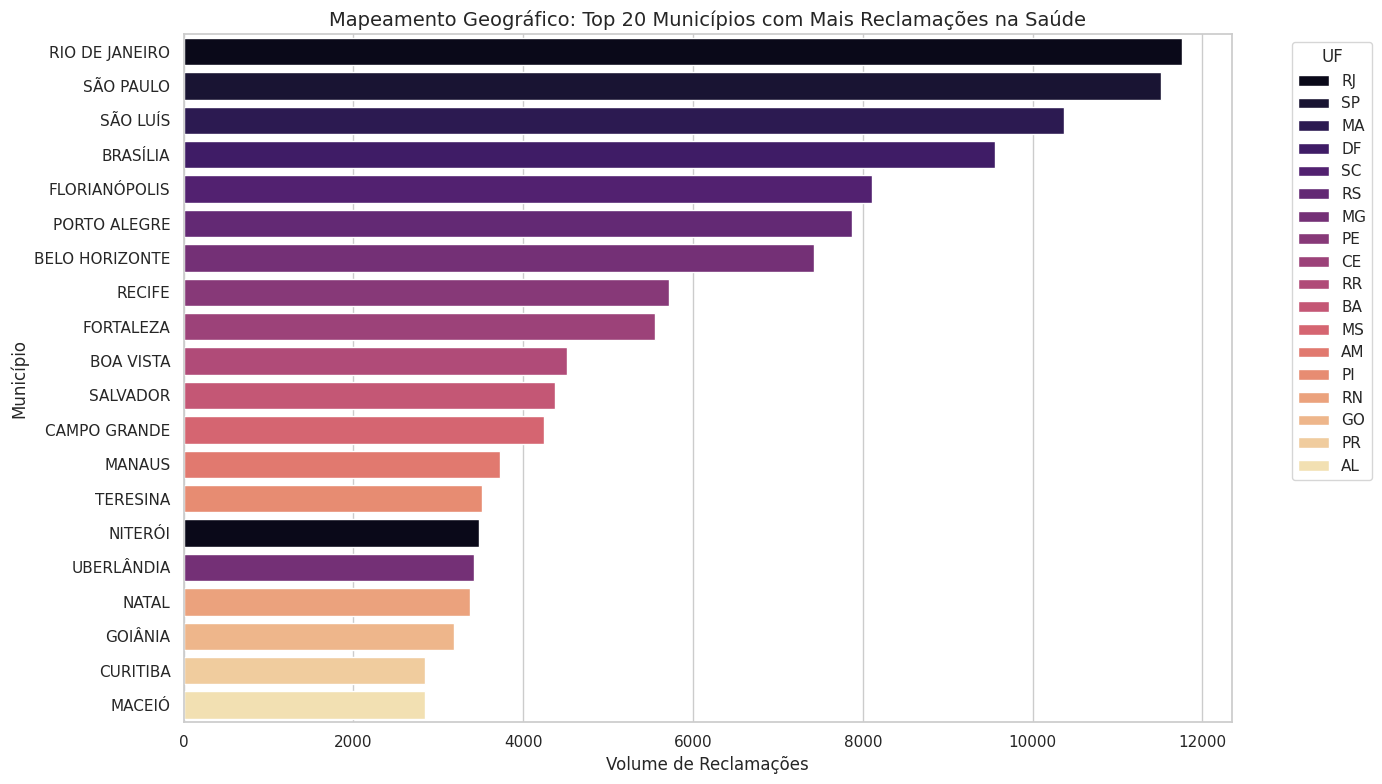

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar o volume de reclamações por UF e Município
# Utilizando a base 'df_saude_reclamacoes' que já filtramos para assuntos de saúde
geo_reclamacoes = df_saude_reclamacoes.groupby(
    ['uf do município manifestação', 'município manifestação']
).size().reset_index(name='Volume_Reclamacoes')

# 2. Filtrar dados inválidos ou não informados
geo_reclamacoes = geo_reclamacoes[
    (geo_reclamacoes['uf do município manifestação'] != 'NI') &
    (geo_reclamacoes['município manifestação'].str.upper() != 'NÃO INFORMADO')
]

# 3. Ordenar para pegar as regiões com mais problemas
top_municipios = geo_reclamacoes.sort_values(by='Volume_Reclamacoes', ascending=False).head(20)

print("--- TOP 20 MUNICÍPIOS COM MAIOR VOLUME DE RECLAMAÇÕES (SAÚDE) ---")
display(top_municipios.reset_index(drop=True))

# 4. Visualização Gráfica do Mapeamento Geográfico
plt.figure(figsize=(14, 8))
sns.barplot(
    data=top_municipios,
    y='município manifestação',
    x='Volume_Reclamacoes',
    hue='uf do município manifestação',
    dodge=False,
    palette='magma'
)

plt.title('Mapeamento Geográfico: Top 20 Municípios com Mais Reclamações na Saúde', fontsize=14)
plt.xlabel('Volume de Reclamações', fontsize=12)
plt.ylabel('Município', fontsize=12)
plt.legend(title='UF', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


Agora, vamos analisar o volume proporcional focado apenas no estado de São Paulo para ver quais cidades do interior ou região metropolitana estão puxando a fila de problemas:

In [29]:
# 1. Filtrar apenas o estado de São Paulo (SP)
geo_sp = geo_reclamacoes[geo_reclamacoes['uf do município manifestação'] == 'SP'].copy()

# 2. Calcular o percentual de cada cidade dentro do estado
total_reclamacoes_sp = geo_sp['Volume_Reclamacoes'].sum()
geo_sp['%_do_Estado'] = (geo_sp['Volume_Reclamacoes'] / total_reclamacoes_sp * 100).round(2)

# 3. Top 15 Cidades de SP
top_cidades_sp = geo_sp.sort_values(by='Volume_Reclamacoes', ascending=False).head(15)

print("--- DESIGUALDADE REGIONAL: TOP 15 CIDADES DE SÃO PAULO ---")
display(top_cidades_sp[['município manifestação', 'Volume_Reclamacoes', '%_do_Estado']].reset_index(drop=True))


--- DESIGUALDADE REGIONAL: TOP 15 CIDADES DE SÃO PAULO ---


,município manifestação,Volume_Reclamacoes,%_do_Estado
0,SÃO PAULO,11518,42.77
1,SÃO CARLOS,983,3.65
2,SÃO JOSÉ DO RIO PRETO,815,3.03
3,GUARULHOS,784,2.91
4,SÃO BERNARDO DO CAMPO,756,2.81
5,CAMPINAS,747,2.77
6,SANTO ANDRÉ,564,2.09
7,RIBEIRÃO PRETO,455,1.69
8,SÃO JOSÉ DOS CAMPOS,417,1.55
9,SOROCABA,391,1.45


### Correlação: Volume de Reclamações vs. Falhas de Infraestrutura por Município
Vamos cruzar o `geo_sp` (que tem as cidades com mais reclamações) com o `df_ocioso` (que contém o inventário de máquinas quebradas ou paradas por falta de profissionais).

--- CORRELAÇÃO: RECLAMAÇÕES VS INFRAESTRUTURA POR MUNICÍPIO (SP) ---


,município_padrao,Volume_Reclamacoes,Hospitais_com_Problema,Equipamentos_Quebrados_Parados
0,SÃO PAULO,11518,4,45
1,BAURU,192,1,27
2,CACHOEIRA PAULISTA,7,1,12
3,ILHA SOLTEIRA,9,1,12
4,SANTO ANDRÉ,564,1,12
5,ITAPEVI,256,1,7
6,SÃO BERNARDO DO CAMPO,756,1,7
7,GUARULHOS,784,1,3
8,OSASCO,353,1,1
9,SÃO JOSÉ DOS CAMPOS,417,1,1


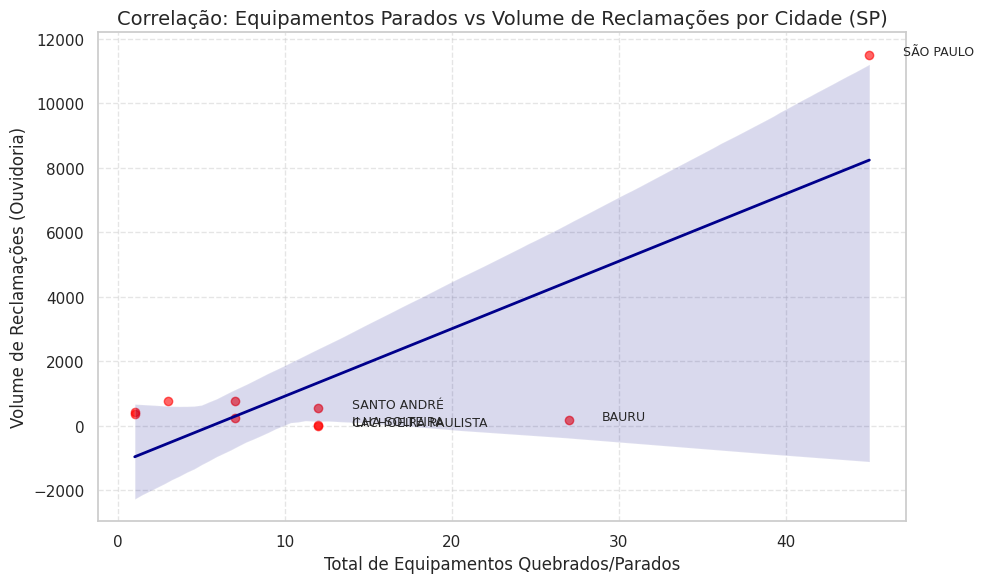

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Criar uma relação Município -> Hospital (usando dados da Ouvidoria)
hosp_mun = df_hospitais[['nome Órgão', 'município manifestação']].dropna().drop_duplicates()

# 2. Usar a 'ponte' do fuzzy match para ligar o nome da Ouvidoria ao nome oficial do CNES
ponte_mun = pd.merge(df_ponte, hosp_mun, left_on='Nome_Ouvidoria', right_on='nome Órgão', how='inner')

# 3. Agrupar equipamentos parados (df_ocioso) por hospital (NO_FANTASIA)
infra_hospital = df_ocioso.groupby('NO_FANTASIA').agg(
    Total_Equipamentos_Parados=('QT_PARADA', 'sum')
).reset_index()

# 4. Cruzar a Infraestrutura com a Cidade do Hospital
infra_cidade = pd.merge(
    ponte_mun,
    infra_hospital,
    left_on='Nome_CNES_Match',
    right_on='NO_FANTASIA',
    how='inner'
)

# 5. Agrupar os problemas de infraestrutura por Município
infra_agrupada_mun = infra_cidade.groupby('município manifestação').agg(
    Hospitais_com_Problema=('NO_FANTASIA', 'nunique'),
    Equipamentos_Quebrados_Parados=('Total_Equipamentos_Parados', 'sum')
).reset_index()

# 6. Cruzar com o volume de reclamações da cidade (geo_sp)
geo_sp['município_padrao'] = geo_sp['município manifestação'].str.upper()
infra_agrupada_mun['município_padrao'] = infra_agrupada_mun['município manifestação'].str.upper()

correlacao_cidades = pd.merge(
    geo_sp[['município_padrao', 'Volume_Reclamacoes']],
    infra_agrupada_mun[['município_padrao', 'Hospitais_com_Problema', 'Equipamentos_Quebrados_Parados']],
    on='município_padrao',
    how='inner'
)

# Ordenar pelas cidades com mais equipamentos parados
correlacao_cidades = correlacao_cidades.sort_values(by='Equipamentos_Quebrados_Parados', ascending=False)

print("--- CORRELAÇÃO: RECLAMAÇÕES VS INFRAESTRUTURA POR MUNICÍPIO (SP) ---")
display(correlacao_cidades.head(15).reset_index(drop=True))

# 7. Visualização Gráfica da Correlação (Scatter Plot)
plt.figure(figsize=(10, 6))
sns.regplot(
    data=correlacao_cidades,
    x='Equipamentos_Quebrados_Parados',
    y='Volume_Reclamacoes',
    scatter_kws={'alpha':0.6, 'color': 'red'},
    line_kws={'color': 'darkblue', 'linewidth': 2}
)

# Adicionar os nomes das 5 principais cidades no gráfico para contexto
top_5_plot = correlacao_cidades.head(5)
for idx, row in top_5_plot.iterrows():
    plt.text(
        row['Equipamentos_Quebrados_Parados'] + 2,
        row['Volume_Reclamacoes'],
        row['município_padrao'],
        fontsize=9
    )

plt.title('Correlação: Equipamentos Parados vs Volume de Reclamações por Cidade (SP)', fontsize=14)
plt.xlabel('Total de Equipamentos Quebrados/Parados', fontsize=12)
plt.ylabel('Volume de Reclamações (Ouvidoria)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Raio-X dos 10 Hospitais Mais Críticos: Falta de Pessoas vs. Infraestrutura
Vamos analisar a fundo os hospitais com maior volume de queixas, classificando o texto das reclamações para descobrir a porcentagem exata de problemas gerados por Recursos Humanos (RH) em comparação com problemas de Infraestrutura e cruzando isso com o inventário real de máquinas paradas.

--- TOP 10 HOSPITAIS: RECLAMAÇÕES VS RAIZ DO PROBLEMA ---


,Hospital,Total de Reclamações,Equip. Parados/Quebrados (CNES),% Queixas: Falta de Pessoas,% Queixas: Equipamento/Infra
0,CLINICA DE FISIOTERAPIA RINCAO,17913,0,76.6%,23.4%
1,HU HOSPITAL UNIVERSITARIO,17050,12,61.8%,38.2%
2,SERVICO DE FISIOTERAPIA,14321,0,83.3%,16.7%
3,CAS,11246,0,66.0%,34.0%
4,COMPLEXO HOSPITALAR DE CLINICAS,8968,0,90.1%,9.9%
5,HOSPITAL SANTA EDWIGES,8701,0,65.0%,35.0%
6,PENITENCIARIA DE FRANCO DA ROCHA III,6158,0,70.5%,29.5%
7,HOSPITAL UNIVERSITARIO I DE MARILIA,6128,1,77.4%,22.6%
8,UNIDADE MOVEL TERRESTRE ONIBUS DE FRANCISCO MO...,5865,0,61.4%,38.6%
9,HOSPITAL SANCTA MAGGIORE,4543,27,67.0%,33.0%


<Figure size 1200x700 with 0 Axes>

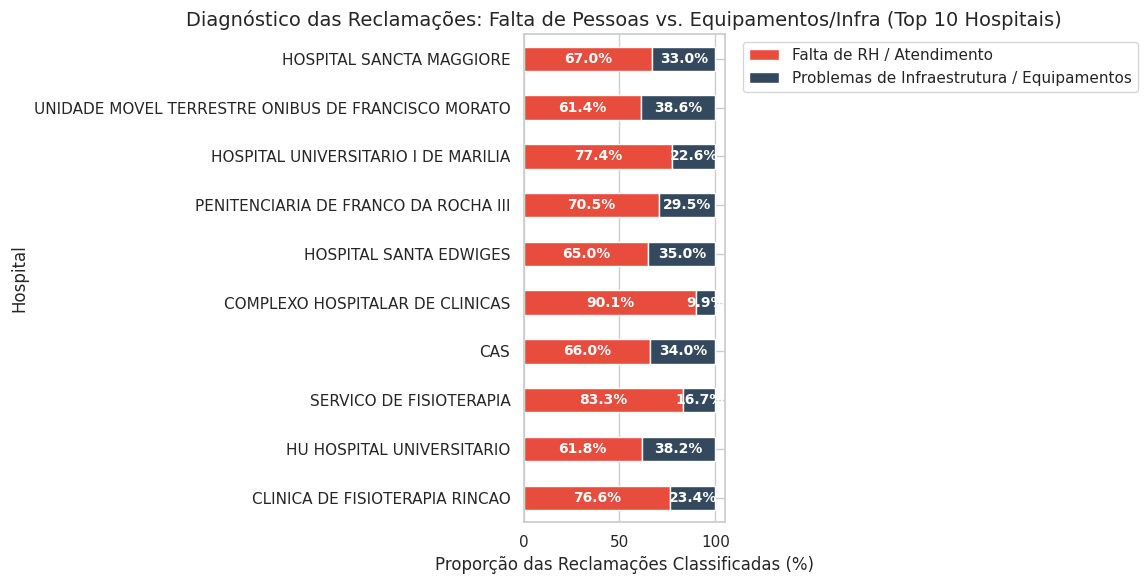

In [33]:
import matplotlib.pyplot as plt
import seaborn as pd
import pandas as pd

# 1. Identificar os 10 hospitais com mais reclamações na base cruzada
top_10_hospitais = df_reclamacoes_cruzadas['Nome_CNES_Match'].value_counts().head(10).index

dados_hospitais = []

for hospital in top_10_hospitais:
    # A. Dados da Ouvidoria (Reclamações)
    reclamacoes_hosp = df_reclamacoes_cruzadas[df_reclamacoes_cruzadas['Nome_CNES_Match'] == hospital]
    total_reclamacoes = len(reclamacoes_hosp)

    # Classificando as reclamações pelo texto (Assunto + Serviço)
    # Juntamos as duas colunas para garantir que a palavra-chave seja encontrada em qualquer parte
    textos = reclamacoes_hosp['assunto'].astype(str).str.lower() + " " + reclamacoes_hosp['serviço'].astype(str).str.lower()

    rh_keywords = 'atendimento|médic|profissional|funcionári|pessoal|demora|enfermeir|recursos humanos|escassez'
    infra_keywords = 'equipamento|aparelho|medicamento|infra|leito|instalaç|estrutura|insumo|material|física|quebrado'

    qtd_rh = textos.str.contains(rh_keywords, na=False).sum()
    qtd_infra = textos.str.contains(infra_keywords, na=False).sum()

    # Normalizar para 100% (Considerando apenas os tickets que se encaixam nesses dois temas centrais)
    total_classificado = qtd_rh + qtd_infra
    if total_classificado > 0:
        perc_rh = (qtd_rh / total_classificado) * 100
        perc_infra = (qtd_infra / total_classificado) * 100
    else:
        perc_rh = 0
        perc_infra = 0

    # B. Dados Físicos (CNES - Realidade)
    # Validar quantos equipamentos estão de fato parados nesse hospital segundo o Ministério da Saúde
    df_ocioso_hosp = df_ocioso[df_ocioso['NO_FANTASIA'] == hospital]
    equipamentos_quebrados = df_ocioso_hosp['QT_PARADA'].sum() if not df_ocioso_hosp.empty else 0

    dados_hospitais.append({
        'Hospital': hospital,
        'Total_Reclamações': total_reclamacoes,
        'Equip_Quebrados_CNES': equipamentos_quebrados,
        'Perc_Falta_RH': round(perc_rh, 1),
        'Perc_Infra': round(perc_infra, 1)
    })

# 2. Criar DataFrame final
df_top10_problemas = pd.DataFrame(dados_hospitais)

# DataFrame para exibição (formatado com o símbolo de %)
df_display = df_top10_problemas.copy()
df_display.columns = ['Hospital', 'Total de Reclamações', 'Equip. Parados/Quebrados (CNES)', '% Queixas: Falta de Pessoas', '% Queixas: Equipamento/Infra']
df_display['% Queixas: Falta de Pessoas'] = df_display['% Queixas: Falta de Pessoas'].astype(str) + '%'
df_display['% Queixas: Equipamento/Infra'] = df_display['% Queixas: Equipamento/Infra'].astype(str) + '%'

print("--- TOP 10 HOSPITAIS: RECLAMAÇÕES VS RAIZ DO PROBLEMA ---")
display(df_display)

# 3. Gráfico de Barras Empilhadas (Visualização das Porcentagens)
plt.figure(figsize=(12, 7))

# Configurando os eixos para o plot
df_plot = df_top10_problemas.set_index('Hospital')
ax = df_plot[['Perc_Falta_RH', 'Perc_Infra']].plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6),
    color=['#e74c3c', '#34495e']
)

plt.title('Diagnóstico das Reclamações: Falta de Pessoas vs. Equipamentos/Infra (Top 10 Hospitais)', fontsize=14)
plt.xlabel('Proporção das Reclamações Classificadas (%)', fontsize=12)
plt.ylabel('Hospital', fontsize=12)
plt.legend(['Falta de RH / Atendimento', 'Problemas de Infraestrutura / Equipamentos'], bbox_to_anchor=(1.05, 1), loc='upper left')

# Adicionar os valores numéricos nas barras para facilitar a leitura visual
for n, (rh, infra) in enumerate(zip(df_plot['Perc_Falta_RH'], df_plot['Perc_Infra'])):
    if rh > 0:
        plt.text(rh/2, n, f"{rh}%", va='center', ha='center', color='white', fontweight='bold', fontsize=10)
    if infra > 0:
        plt.text(rh + (infra/2), n, f"{infra}%", va='center', ha='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


### Cruzamento: Queixas de Falta de Profissionais vs. Quadro Real de Funcionários (CNES)
Vamos pegar nossos 10 hospitais mais críticos e cruzar com a base de Recursos Humanos do Ministério da Saúde (`df_rh_geral`) para contar quantos Médicos (CBO 225) e Enfermeiros/Técnicos (CBOs 2235, 3222) estão registrados em cada unidade.

In [34]:
import pandas as pd

# 1. Pegar os nomes do Top 10 Hospitais já calculados no passo anterior
hospitais_alvo = df_top10_problemas['Hospital'].tolist()

# 2. Localizar o código oficial (CO_UNIDADE) desses hospitais na base de SP (df_hospitais_sp)
df_hospitais_alvo = df_hospitais_sp[df_hospitais_sp['NO_FANTASIA'].isin(hospitais_alvo)][['CO_UNIDADE', 'NO_FANTASIA', 'CO_CNES']].drop_duplicates(subset=['NO_FANTASIA'])

# Criar a CHAVE_MATCH (7 últimos dígitos) para cruzar com a base de RH
df_hospitais_alvo['CHAVE_MATCH'] = df_hospitais_alvo['CO_UNIDADE'].astype(str).str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

# 3. Filtrar a base geral de RH apenas para profissionais de atendimento direto
# Prefixos CBO: 225 (Médicos), 2235 (Enfermeiros), 3222 (Técnicos de Enfermagem)
cbos_assistenciais = ('225', '2235', '3222')

print("Filtrando profissionais assistenciais na base do CNES...")
df_rh_assistencial = df_rh_geral[df_rh_geral['CO_CBO'].str.startswith(cbos_assistenciais, na=False)].copy()

# Criar a CHAVE_MATCH na base de RH
df_rh_assistencial['CHAVE_MATCH'] = df_rh_assistencial['CO_UNIDADE'].str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(7).str[-7:]

# 4. Agrupar a quantidade de profissionais por estabelecimento
contagem_staff = df_rh_assistencial.groupby('CHAVE_MATCH').agg(
    Total_Medicos_Enfermeiros=('CO_CBO', 'count')
).reset_index()

# 5. Cruzar o quadro de funcionários com os hospitais do Top 10
quadro_real = pd.merge(df_hospitais_alvo, contagem_staff, on='CHAVE_MATCH', how='left')
quadro_real['Total_Medicos_Enfermeiros'] = quadro_real['Total_Medicos_Enfermeiros'].fillna(0).astype(int)

# 6. Juntar com as estatísticas de reclamações geradas no script anterior
diagnostico_rh = pd.merge(df_top10_problemas, quadro_real[['NO_FANTASIA', 'Total_Medicos_Enfermeiros']],
                          left_on='Hospital', right_on='NO_FANTASIA', how='left').drop(columns=['NO_FANTASIA'])

# Criar um indicador simples: Reclamações por Profissional (Pressão Percebida)
# Evitar divisão por zero
diagnostico_rh['Queixas_por_Profissional'] = diagnostico_rh.apply(
    lambda x: round(x['Total_Reclamações'] / x['Total_Medicos_Enfermeiros'], 2) if x['Total_Medicos_Enfermeiros'] > 0 else 'Alerta: Sem Registro de RH',
    axis=1
)

print("\n--- VALIDAÇÃO DE ALOCAÇÃO DE RECURSOS: TOP 10 HOSPITAIS ---")
display(diagnostico_rh[['Hospital', 'Total_Reclamações', 'Perc_Falta_RH', 'Total_Medicos_Enfermeiros', 'Queixas_por_Profissional']])


Filtrando profissionais assistenciais na base do CNES...

--- VALIDAÇÃO DE ALOCAÇÃO DE RECURSOS: TOP 10 HOSPITAIS ---


,Hospital,Total_Reclamações,Perc_Falta_RH,Total_Medicos_Enfermeiros,Queixas_por_Profissional
0,CLINICA DE FISIOTERAPIA RINCAO,17913,76.6,0,Alerta: Sem Registro de RH
1,HU HOSPITAL UNIVERSITARIO,17050,61.8,822,20.74
2,SERVICO DE FISIOTERAPIA,14321,83.3,0,Alerta: Sem Registro de RH
3,CAS,11246,66.0,0,Alerta: Sem Registro de RH
4,COMPLEXO HOSPITALAR DE CLINICAS,8968,90.1,2258,3.97
5,HOSPITAL SANTA EDWIGES,8701,65.0,0,Alerta: Sem Registro de RH
6,PENITENCIARIA DE FRANCO DA ROCHA III,6158,70.5,12,513.17
7,HOSPITAL UNIVERSITARIO I DE MARILIA,6128,77.4,0,Alerta: Sem Registro de RH
8,UNIDADE MOVEL TERRESTRE ONIBUS DE FRANCISCO MO...,5865,61.4,0,Alerta: Sem Registro de RH
9,HOSPITAL SANCTA MAGGIORE,4543,67.0,536,8.48


/tmp/ipykernel_451/3236740517.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


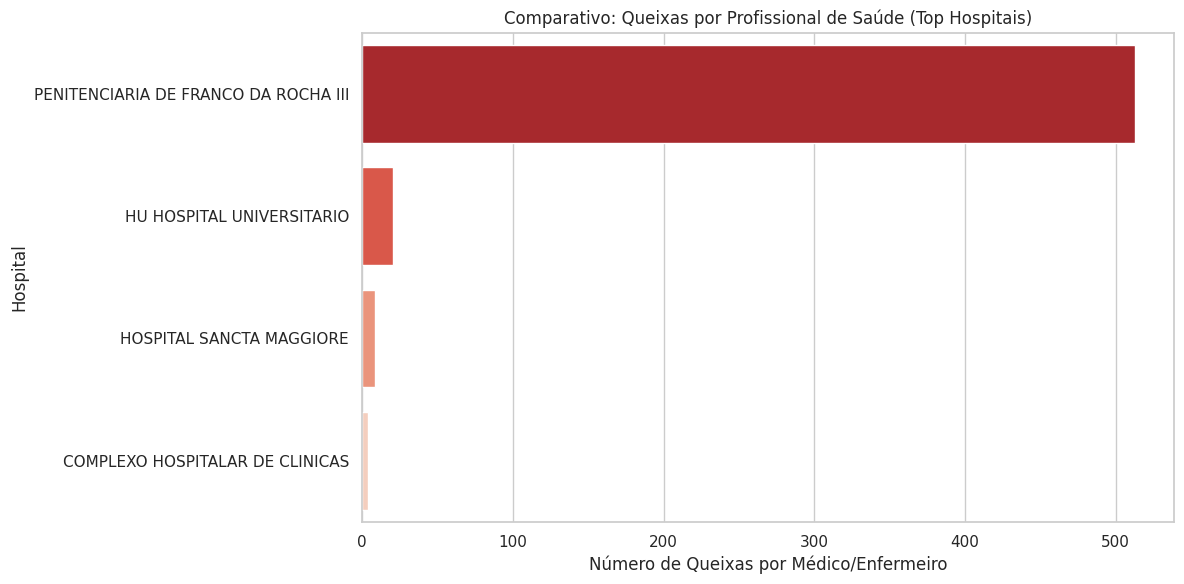

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar os hospitais que têm dados válidos para 'Queixas_por_Profissional'
# Vamos remover os que têm a string 'Alerta: Sem Registro de RH'
df_grafico_rh = diagnostico_rh[diagnostico_rh['Queixas_por_Profissional'] != 'Alerta: Sem Registro de RH'].copy()

# Garantir que a coluna seja numérica para plotar
df_grafico_rh['Queixas_por_Profissional'] = df_grafico_rh['Queixas_por_Profissional'].astype(float)

# Ordenar do maior para o menor
df_grafico_rh = df_grafico_rh.sort_values(by='Queixas_por_Profissional', ascending=False)

# Plotar o gráfico
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_grafico_rh,
    x='Queixas_por_Profissional',
    y='Hospital',
    palette='Reds_r'
)

plt.title('Comparativo: Queixas por Profissional de Saúde (Top Hospitais)')
plt.xlabel('Número de Queixas por Médico/Enfermeiro')
plt.ylabel('Hospital')
plt.tight_layout()
plt.show()


--- RELAÇÃO: QUEIXAS DE INFRAESTRUTURA VS EQUIPAMENTOS PARADOS ---


,Hospital,Perc_Infra,Equip_Quebrados_CNES,Total_Reclamações
8,UNIDADE MOVEL TERRESTRE ONIBUS DE FRANCISCO MO...,38.6,0,5865
1,HU HOSPITAL UNIVERSITARIO,38.2,12,17050
5,HOSPITAL SANTA EDWIGES,35.0,0,8701
3,CAS,34.0,0,11246
9,HOSPITAL SANCTA MAGGIORE,33.0,27,4543
6,PENITENCIARIA DE FRANCO DA ROCHA III,29.5,0,6158
0,CLINICA DE FISIOTERAPIA RINCAO,23.4,0,17913
7,HOSPITAL UNIVERSITARIO I DE MARILIA,22.6,1,6128
2,SERVICO DE FISIOTERAPIA,16.7,0,14321
4,COMPLEXO HOSPITALAR DE CLINICAS,9.9,0,8968


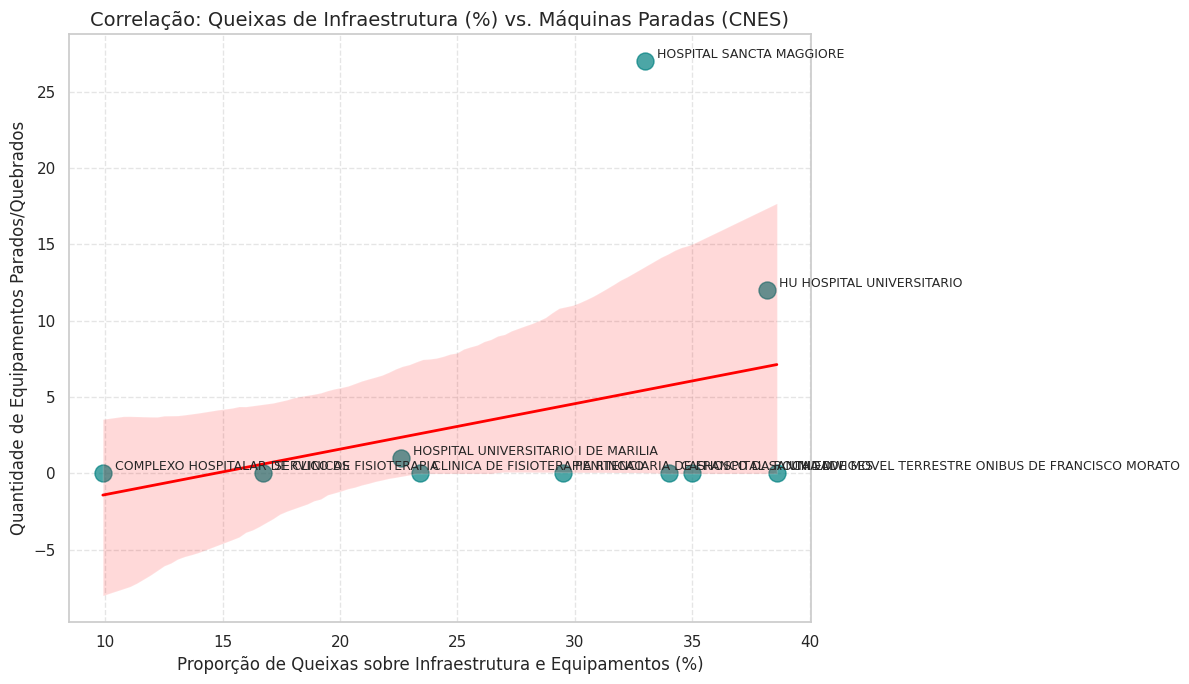

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que as colunas estão no formato numérico adequado
df_top10_problemas['Perc_Infra'] = df_top10_problemas['Perc_Infra'].astype(float)
df_top10_problemas['Equip_Quebrados_CNES'] = df_top10_problemas['Equip_Quebrados_CNES'].astype(int)

# 2. Ordenar os dados para exibição na tabela
df_analise_infra = df_top10_problemas.sort_values(by='Perc_Infra', ascending=False)

print("--- RELAÇÃO: QUEIXAS DE INFRAESTRUTURA VS EQUIPAMENTOS PARADOS ---")
display(df_analise_infra[['Hospital', 'Perc_Infra', 'Equip_Quebrados_CNES', 'Total_Reclamações']])

# 3. Criar o gráfico de dispersão (Scatter Plot) com linha de tendência
plt.figure(figsize=(12, 7))
sns.regplot(
    data=df_top10_problemas,
    x='Perc_Infra',
    y='Equip_Quebrados_CNES',
    scatter_kws={'s': 150, 'color': 'teal', 'alpha': 0.7},
    line_kws={'color': 'red', 'linewidth': 2}
)

# Adicionar os nomes dos hospitais aos pontos para facilitar a identificação
for idx, row in df_top10_problemas.iterrows():
    plt.text(
        row['Perc_Infra'] + 0.5,
        row['Equip_Quebrados_CNES'] + 0.2,
        row['Hospital'],
        fontsize=9
    )

plt.title('Correlação: Queixas de Infraestrutura (%) vs. Máquinas Paradas (CNES)', fontsize=14)
plt.xlabel('Proporção de Queixas sobre Infraestrutura e Equipamentos (%)', fontsize=12)
plt.ylabel('Quantidade de Equipamentos Parados/Quebrados', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


--- TOP 10 EQUIPAMENTOS MAIS ASSOCIADOS A COLAPSOS DE INFRAESTRUTURA ---


,DS_TIPO_EQUIPAMENTO,Hospitais_Afetados,Total_Maquinas_Paradas,Volume_Queixas_Associadas,Score_Impacto_Global
0,REABILITACAO,2,2,502,502
1,MANUTENCAO DA VIDA,1,1,134,134


/tmp/ipykernel_451/3863797201.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


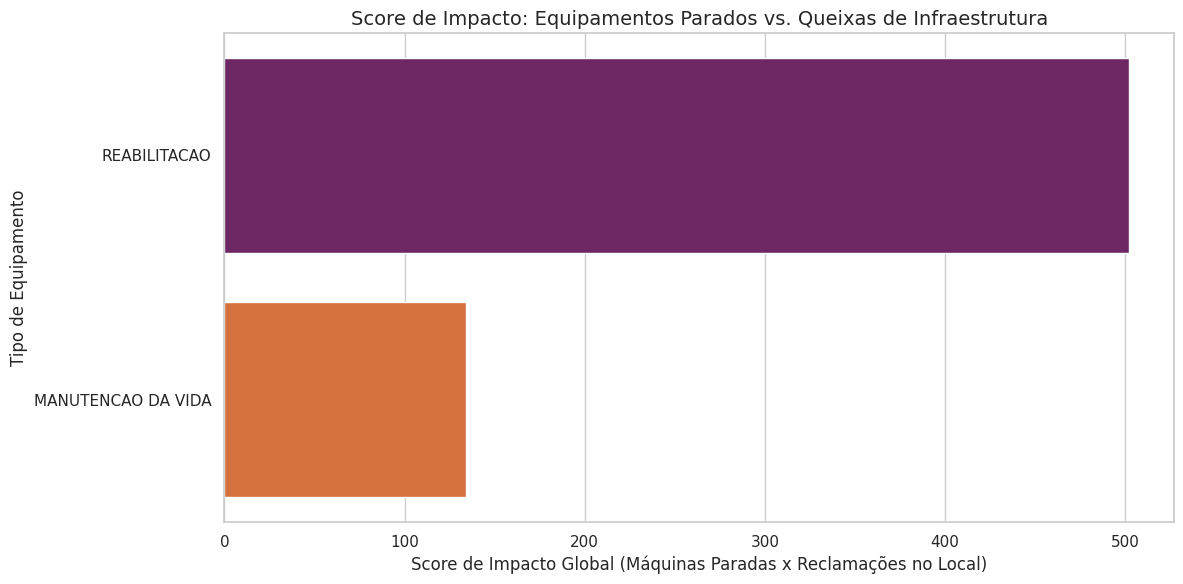

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Isolar apenas as queixas de infraestrutura na base cruzada
infra_keywords = 'equipamento|aparelho|medicamento|infra|leito|instalaç|estrutura|insumo|material|física|quebrado'
textos_reclamacoes = df_reclamacoes_cruzadas['assunto'].astype(str).str.lower() + " " + df_reclamacoes_cruzadas['serviço'].astype(str).str.lower()

df_queixas_infra = df_reclamacoes_cruzadas[textos_reclamacoes.str.contains(infra_keywords, na=False)]

# 2. Contar volume de queixas de infraestrutura por hospital
vol_infra_hosp = df_queixas_infra.groupby('Nome_CNES_Match').size().reset_index(name='Total_Queixas_Infra')

# 3. Cruzar com a base de equipamentos parados (df_ocioso)
cruzamento_equip_queixas = pd.merge(
    vol_infra_hosp,
    df_ocioso[['NO_FANTASIA', 'DS_TIPO_EQUIPAMENTO', 'QT_PARADA']],
    left_on='Nome_CNES_Match',
    right_on='NO_FANTASIA',
    how='inner'
)

# 4. Criar o "Score de Impacto"
# (Quantidade de Máquinas Paradas) * (Volume de Queixas de Infraestrutura no Local)
cruzamento_equip_queixas['Score_Impacto'] = cruzamento_equip_queixas['Total_Queixas_Infra'] * cruzamento_equip_queixas['QT_PARADA']

# 5. Agrupar por Tipo de Equipamento para ver quais causam mais "Dor"
impacto_por_equipamento = cruzamento_equip_queixas.groupby('DS_TIPO_EQUIPAMENTO').agg(
    Hospitais_Afetados=('NO_FANTASIA', 'nunique'),
    Total_Maquinas_Paradas=('QT_PARADA', 'sum'),
    Volume_Queixas_Associadas=('Total_Queixas_Infra', 'sum'),
    Score_Impacto_Global=('Score_Impacto', 'sum')
).sort_values(by='Score_Impacto_Global', ascending=False).reset_index()

print("--- TOP 10 EQUIPAMENTOS MAIS ASSOCIADOS A COLAPSOS DE INFRAESTRUTURA ---")
display(impacto_por_equipamento.head(10))

# 6. Visualização Gráfica do Impacto
plt.figure(figsize=(12, 6))
sns.barplot(
    data=impacto_por_equipamento.head(10),
    x='Score_Impacto_Global',
    y='DS_TIPO_EQUIPAMENTO',
    palette='inferno'
)

plt.title('Score de Impacto: Equipamentos Parados vs. Queixas de Infraestrutura', fontsize=14)
plt.xlabel('Score de Impacto Global (Máquinas Paradas x Reclamações no Local)', fontsize=12)
plt.ylabel('Tipo de Equipamento', fontsize=12)
plt.tight_layout()
plt.show()
